![logo](https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/images/notebook-logo.png)

## **Curso**: Residência em Inteligência Artificial
## **Unidade Curricular**: Séries Temporais
## **Professor**: Matheus Vanzan
---

### Setup

* `numpy` (`np`): cálculos numéricos
* `pandas` (`pd`): tabelas (`DataFrame`) e séries (`Series`)
* `matplotlib.pyplot` (`plt`): gráficos
* `statsmodels`: modelos estatísticos de séries temporais (decomposição e suavização exponencial)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing

`PATH` é o endereço base dos dados (um repositório no GitHub). Em cada leitura, somamos a ele o caminho do arquivo.

In [ ]:
PATH = 'https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/'

## 📌 1 - Decomposição

Na Aula 1 **reconhecemos** os componentes olhando o gráfico, com um método intuitivo. Agora vamos **estimá-los** e separá-los. A **decomposição** divide a série em três partes: tendência, sazonalidade e **resíduo** (o que sobra depois de retirar as outras duas).

> **Dataset:** o **consumo industrial** da Aula 1 (potência da planta A, em kW), agora em média **diária**. É a série em que a sazonalidade semanal aparece com clareza.

### 1.1 - Preparando a série

Lemos o arquivo com os mesmos argumentos da Aula 1:

In [ ]:
df = pd.read_csv(PATH + 'datasets/consumo_energia_industrial.csv', parse_dates=['timestamp'], index_col='timestamp')
potencia = df['potencia_kw']
potencia.head()

,potencia_kw
timestamp,
2024-01-01 00:00:00,150.2
2024-01-01 00:15:00,143.3
2024-01-01 00:30:00,152.6
2024-01-01 00:45:00,153.6
2024-01-01 01:00:00,138.5


O dataset **puro**: uma medida a cada 15 minutos, no ano todo:

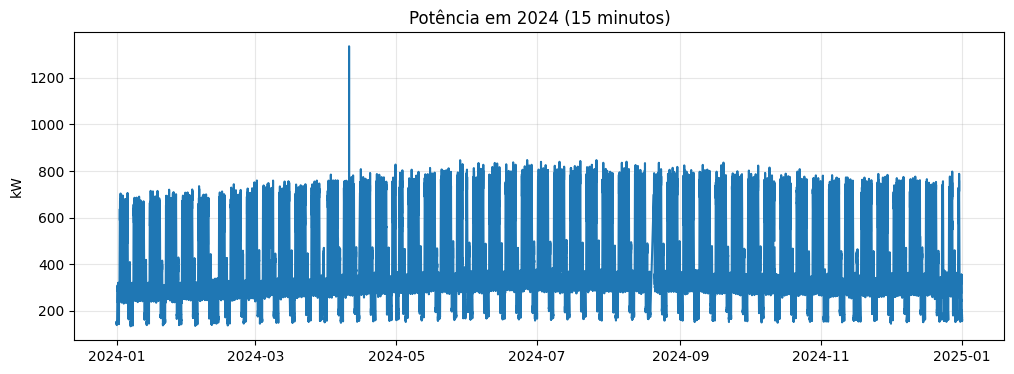

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(potencia.index, potencia.values)
plt.title('Potência em 2024 (15 minutos)')
plt.ylabel('kW')
plt.grid(alpha=0.3)
plt.show()

São cerca de 35 mil pontos, uma massa densa difícil de ler. Para decompor, queremos **um valor por dia**: assim o ciclo semanal tem 7 pontos (o período $m = 7$), em vez de 672 (7 dias, com 96 medidas por dia). Com `resample('D').mean()` (da Aula 1), calculamos a média de cada dia:

In [ ]:
diario = potencia.resample('D').mean()
diario.head()

,potencia_kw
timestamp,
2024-01-01,227.168750
2024-01-02,448.893750
2024-01-03,449.222917
2024-01-04,451.777083
2024-01-05,449.950000


A decomposição não aceita valores ausentes, e a série tem um dia sem nenhuma medida (a lacuna que vimos na Aula 1, em 19/08). Com `.interpolate()`, esse dia recebe um valor calculado entre o dia anterior e o seguinte. Os dias ao redor dele, depois de preenchido:

In [ ]:
diario = diario.interpolate()
diario.loc['2024-08-17':'2024-08-21']

,potencia_kw
timestamp,
2024-08-17,332.271875
2024-08-18,259.012500
2024-08-19,412.654167
2024-08-20,566.295833
2024-08-21,528.677083


A série diária:

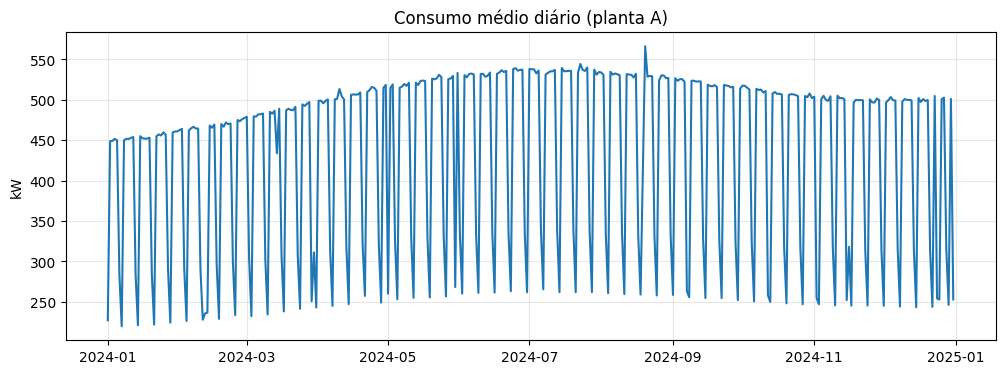

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(diario.index, diario.values)
plt.title('Consumo médio diário (planta A)')
plt.ylabel('kW')
plt.grid(alpha=0.3)
plt.show()

Os dias úteis têm consumo alto e os fins de semana, baixo: o ciclo se repete a cada **7 dias**. O período é $m = 7$.

### 1.2 - Decomposição clássica

A função `seasonal_decompose` do `statsmodels` estima os três componentes de uma vez. No método clássico:

* **Tendência:** média da janela centrada, com o tamanho do período $m$ (com $m$ par, as duas pontas da janela pesam $1/2$)
* **Sazonalidade:** média de cada posição do ciclo (todas as segundas, todas as terças...), ajustada para ter média zero
* **Resíduo:** o que sobra

O resultado guarda os componentes em `.observed`, `.trend`, `.seasonal` e `.resid`.

#### 1.2.1 - Modelo aditivo

No modelo aditivo, a série é a soma dos componentes:

$$x_t = T_t + S_t + R_t \qquad R_t = x_t - T_t - S_t$$

Aplicando ao consumo diário. Os argumentos da função estão explicados no código:

In [ ]:
resultado = seasonal_decompose(
    # série a decompor
    diario,

    # modelo: 'additive' (x = T + S + R) ou 'multiplicative' (x = T × S × R)
    model='additive',

    # período m: quantos pontos tem um ciclo (aqui, 7 dias)
    period=7,
)

Os componentes, reunidos em uma tabela. A **tendência** fica sem valor nos 3 primeiros dias (e nos 3 últimos), porque a janela centrada de 7 dias precisa de 3 dias de cada lado. A **sazonalidade** é o padrão da semana repetido (a série começa em uma segunda-feira, então os 7 primeiros valores vão de segunda a domingo). O **resíduo** é o que sobra:

In [ ]:
pd.DataFrame({
    'observada': resultado.observed,
    'tendência': resultado.trend,
    'sazonalidade': resultado.seasonal,
    'resíduo': resultado.resid
}).head(8)

,observada,tendência,sazonalidade,resíduo
timestamp,,,,
2024-01-01,227.168750,NaN,63.026595,NaN
2024-01-02,448.893750,NaN,61.169508,NaN
2024-01-03,449.222917,NaN,60.625664,NaN
2024-01-04,451.777083,361.552965,64.166305,26.057813
2024-01-05,449.950000,393.371864,60.541341,-3.963205
2024-01-06,284.092632,393.788531,-120.877902,11.182003
2024-01-07,219.765625,394.122162,-188.651510,14.294974
2024-01-08,449.901042,394.291953,63.026595,-7.417507


Os quatro componentes, cada um em um painel (série observada, tendência, sazonalidade e resíduo):

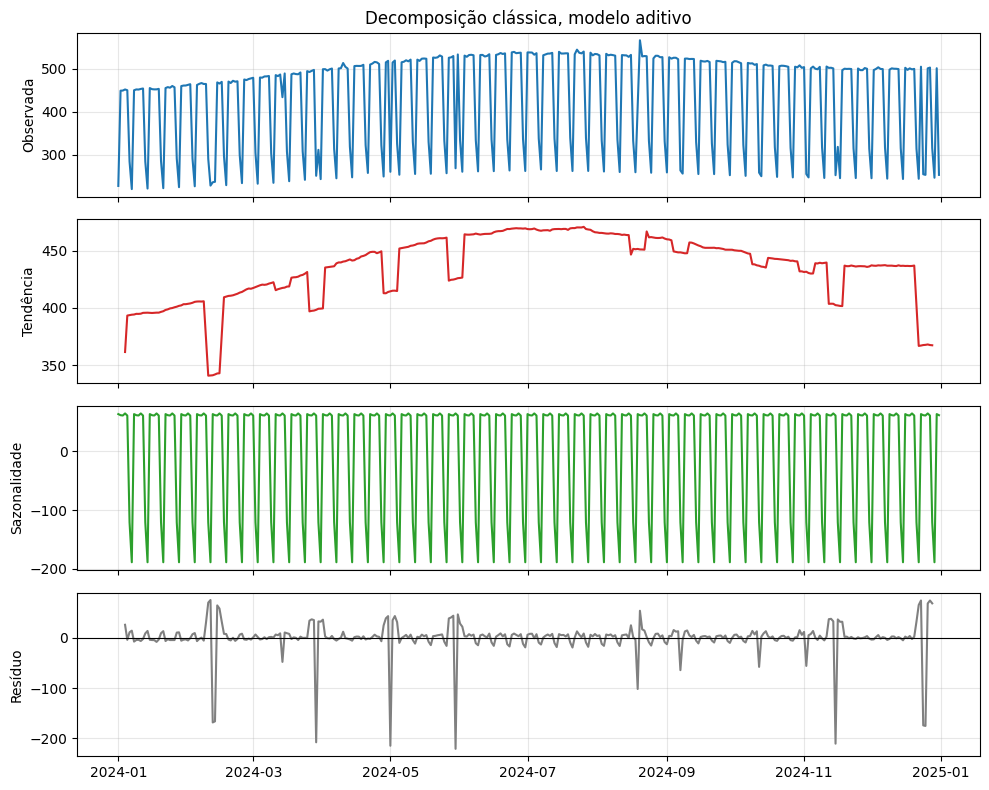

In [ ]:
fig, eixos = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
eixos[0].plot(resultado.observed, color='tab:blue')
eixos[0].set_title('Decomposição clássica, modelo aditivo')
eixos[0].set_ylabel('Observada')
eixos[1].plot(resultado.trend, color='tab:red')
eixos[1].set_ylabel('Tendência')
eixos[2].plot(resultado.seasonal, color='tab:green')
eixos[2].set_ylabel('Sazonalidade')
eixos[3].plot(resultado.resid, color='gray')
eixos[3].axhline(0, color='black', linewidth=0.8)
eixos[3].set_ylabel('Resíduo')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

No gráfico vemos: a tendência é suave, a sazonalidade repete o padrão semanal e o resíduo oscila em torno de 0, sem o ciclo semanal. Os ciclos de prazo longo, quando existem, ficam juntos da tendência.

> A média da janela centrada **perde pontos nas pontas**: a tendência não existe na metade da janela em cada ponta.

#### 1.2.2 - Modelo multiplicativo

> **Dataset:** o **AirPassengers** da Aula 1 (passageiros por mês, de 1949 a 1960), a série em que a amplitude da sazonalidade cresce com o nível.

Carregamos com os argumentos que já conhecemos. O `.asfreq` (da Aula 1) declara a frequência do índice, e os modelos do `statsmodels` usam essa informação:

In [ ]:
df_air = pd.read_csv(
    PATH + 'datasets/air_passengers.csv',
    names=['Mes', 'Passageiros'],
    header=0,
    parse_dates=['Mes'],
    index_col='Mes',
)
passageiros = df_air['Passageiros'].asfreq(
    # frequência do índice: 'MS' = mensal, com as datas no início do mês
    'MS',
)
passageiros.head()

,Passageiros
Mes,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


A série pura:

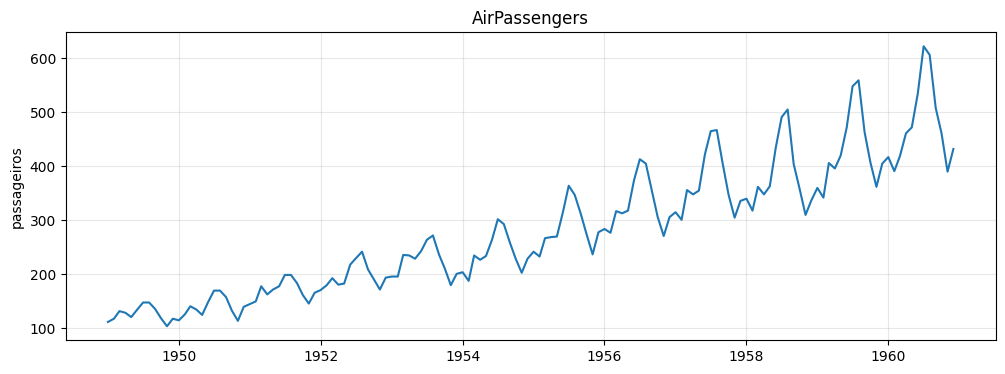

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(passageiros.index, passageiros.values)
plt.title('AirPassengers')
plt.ylabel('passageiros')
plt.grid(alpha=0.3)
plt.show()

No modelo multiplicativo, $x_t = T_t \times S_t \times R_t$. A decomposição troca a subtração pela **divisão**: a sazonalidade é a média de $x / T$ em cada mês, e o resíduo é $x / (T \times S)$. A sazonalidade vira um **fator** (por exemplo, 1,2 em vez de +50), e o resíduo oscila em torno de **1**. Basta mudar o `model`; o período agora é 12 (meses):

In [ ]:
resultado_mult = seasonal_decompose(
    passageiros,
    model='multiplicative',
    period=12
)

Os componentes, reunidos em uma tabela. A sazonalidade e o resíduo são **fatores** (em torno de 1). Com período 12, a tendência fica sem valor nos 6 primeiros meses (e nos 6 últimos), a metade da janela:

In [ ]:
pd.DataFrame({
    'observada': resultado_mult.observed,
    'tendência': resultado_mult.trend,
    'sazonalidade': resultado_mult.seasonal,
    'resíduo': resultado_mult.resid
}).head(8)

,observada,tendência,sazonalidade,resíduo
Mes,,,,
1949-01-01,112.0,NaN,0.910230,NaN
1949-02-01,118.0,NaN,0.883625,NaN
1949-03-01,132.0,NaN,1.007366,NaN
1949-04-01,129.0,NaN,0.975906,NaN
1949-05-01,121.0,NaN,0.981378,NaN
1949-06-01,135.0,NaN,1.112776,NaN
1949-07-01,148.0,126.791667,1.226556,0.951664
1949-08-01,148.0,127.250000,1.219911,0.953401


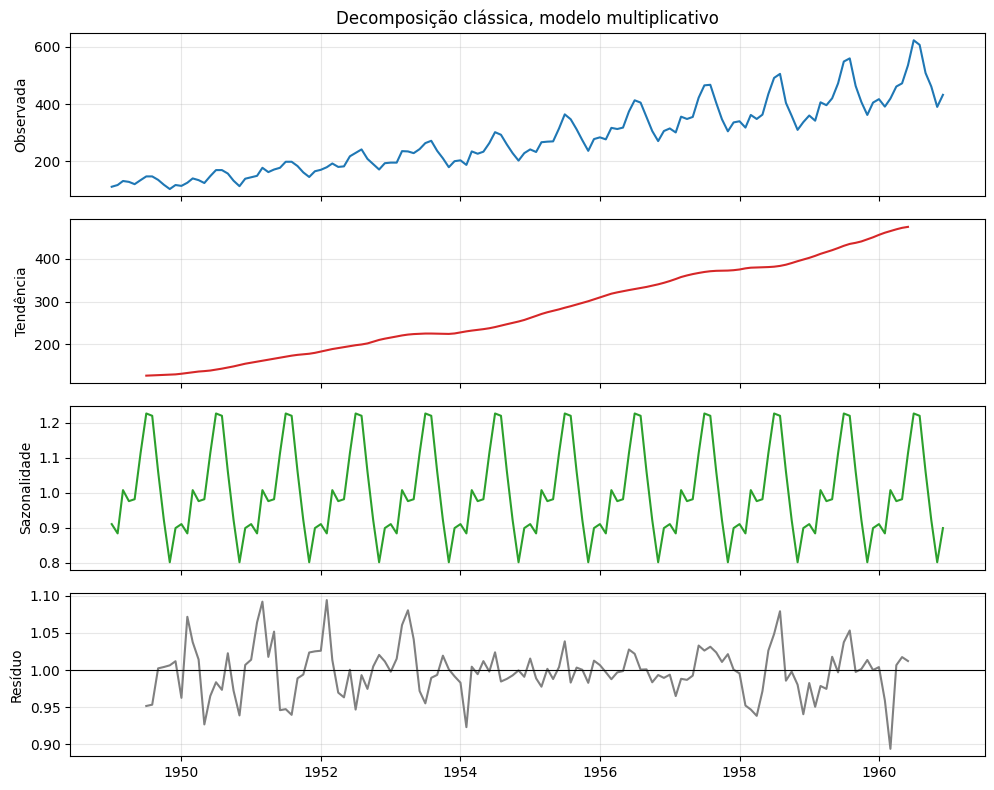

In [ ]:
fig, eixos = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
eixos[0].plot(resultado_mult.observed, color='tab:blue')
eixos[0].set_title('Decomposição clássica, modelo multiplicativo')
eixos[0].set_ylabel('Observada')
eixos[1].plot(resultado_mult.trend, color='tab:red')
eixos[1].set_ylabel('Tendência')
eixos[2].plot(resultado_mult.seasonal, color='tab:green')
eixos[2].set_ylabel('Sazonalidade')
eixos[3].plot(resultado_mult.resid, color='gray')
eixos[3].axhline(1, color='black', linewidth=0.8)
eixos[3].set_ylabel('Resíduo')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

As diferenças entre os dois modelos:

* **Modelo:** aditivo, $x = T + S + R$; multiplicativo, $x = T \times S \times R$
* **Tendência:** igual nos dois, a média da janela centrada em $t$
* **Retirar a tendência:** $x - T$ no aditivo e $x \div T$ no multiplicativo
* **Sazonalidade:** média por posição, com média 0 no aditivo e com média 1 (um fator) no multiplicativo
* **Resíduo:** $x - T - S$ no aditivo (em torno de 0) e $x \div (T \times S)$ no multiplicativo (em torno de 1)
* **Quando usar:** amplitude constante no aditivo, e amplitude que cresce com o nível no multiplicativo

#### 1.2.3 - Análise dos resíduos

O resíduo deve parecer **ruído**. Se tiver padrão, a decomposição não capturou tudo. Vamos decompor o AirPassengers com os **dois** modelos e comparar os resíduos. Primeiro o modelo aditivo, o mais simples:

In [ ]:
resultado_adit = seasonal_decompose(passageiros, model='additive', period=12)

In [ ]:
pd.DataFrame({
    'aditivo': resultado_adit.resid,
    'multiplicativo':
    resultado_mult.resid
}).dropna().head()

,aditivo,multiplicativo
Mes,,
1949-07-01,-42.622475,0.951664
1949-08-01,-42.073232,0.953401
1949-09-01,-8.478535,1.002220
1949-10-01,11.059343,1.004028
1949-11-01,28.593434,1.006270


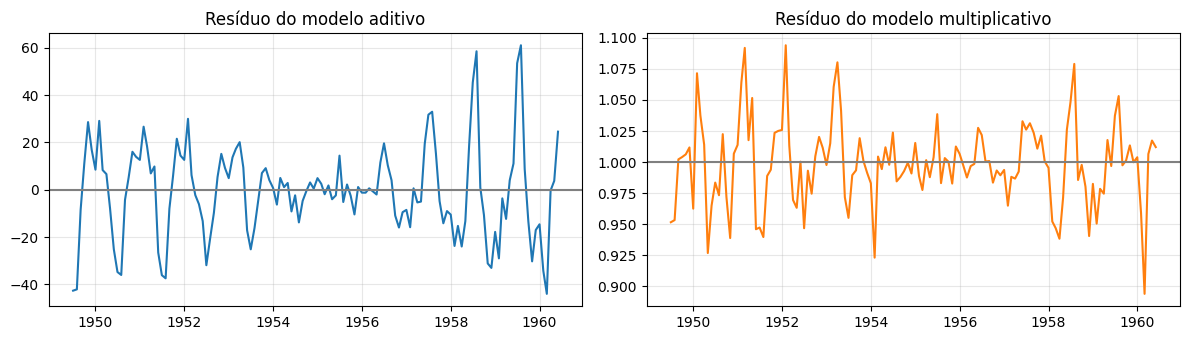

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))
eixos[0].plot(resultado_adit.resid)
eixos[0].axhline(0, color='gray')
eixos[0].set_title('Resíduo do modelo aditivo')
eixos[1].plot(resultado_mult.resid, color='tab:orange')
eixos[1].axhline(1, color='gray')
eixos[1].set_title('Resíduo do modelo multiplicativo')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

No gráfico vemos:

* **Aditivo:** o resíduo tem ondas regulares, com amplitude irregular (de -44 a 61). É a sazonalidade que o modelo não capturou
* **Multiplicativo:** o resíduo oscila em torno de 1, sem padrão aparente, e a variação é pequena (de 0,89 a 1,09)

Isso reforça o que a razão amplitude / média indicou na Aula 1: o modelo **multiplicativo** descreve melhor a sazonalidade do AirPassengers. O tipo identificado orienta como decompor.

### 1.3 - Decomposição STL

O **STL** (*Seasonal-Trend decomposition using LOESS*) é outro método de decomposição, com o mesmo resultado (tendência, sazonalidade e resíduo) e outra forma de estimar:

* **LOESS:** é uma **regressão local**. Para estimar cada ponto, ajusta uma reta com os pontos vizinhos, dando mais peso aos mais próximos, em vez de tirar a média simples
* **Sazonalidade:** em vez da média de cada posição do ciclo (todos os janeiros, todos os fevereiros), o STL **suaviza** cada grupo ao longo dos anos
* **Consequência 1:** a sazonalidade pode **mudar ao longo do tempo**
* **Consequência 2:** a série é estimada **inteira**, sem perder pontos nas pontas

> **Só aditivo:** o STL trabalha só com o modelo aditivo, $x_t = T_t + S_t + R_t$. Para uma série multiplicativa, aplicamos um truque com logaritmo (item 1.3.2).

O `.fit()` calcula os componentes, que ficam em `.observed`, `.trend`, `.seasonal` e `.resid`.

> **`.fit()`:** no `seasonal_decompose`, a própria função já calcula e devolve o resultado. O `STL` é uma **classe**: `STL(...)` só cria o objeto com a configuração, e o `.fit()` é que faz o cálculo. É o mesmo padrão do `scikit-learn` (criar o modelo e chamar `.fit()`) e dos modelos de suavização exponencial que vamos usar adiante.

#### 1.3.1 - Modelo aditivo

Aplicando ao consumo diário. Os argumentos de `STL` estão explicados no código:

In [ ]:
stl_consumo = STL(
    # série a decompor
    diario,

    # período m: quantos pontos tem um ciclo (aqui, 7 dias)
    period=7,

    # True: versão robusta, que reduz a influência de pontos atípicos
    robust=True,
).fit()

Os componentes, reunidos em uma tabela. Diferente da clássica, o STL tem tendência em todos os dias, inclusive nas pontas:

In [ ]:
pd.DataFrame({
    'observada': stl_consumo.observed,
    'tendência': stl_consumo.trend,
    'sazonalidade': stl_consumo.seasonal,
    'resíduo': stl_consumo.resid
}).head()

,observada,tendência,sazonalidade,resíduo
timestamp,,,,
2024-01-01,227.168750,392.448885,55.278479,-220.558614
2024-01-02,448.893750,392.711240,56.315348,-0.132837
2024-01-03,449.222917,392.974986,56.136065,0.111865
2024-01-04,451.777083,393.241322,58.089458,0.446303
2024-01-05,449.950000,393.510807,56.897079,-0.457886


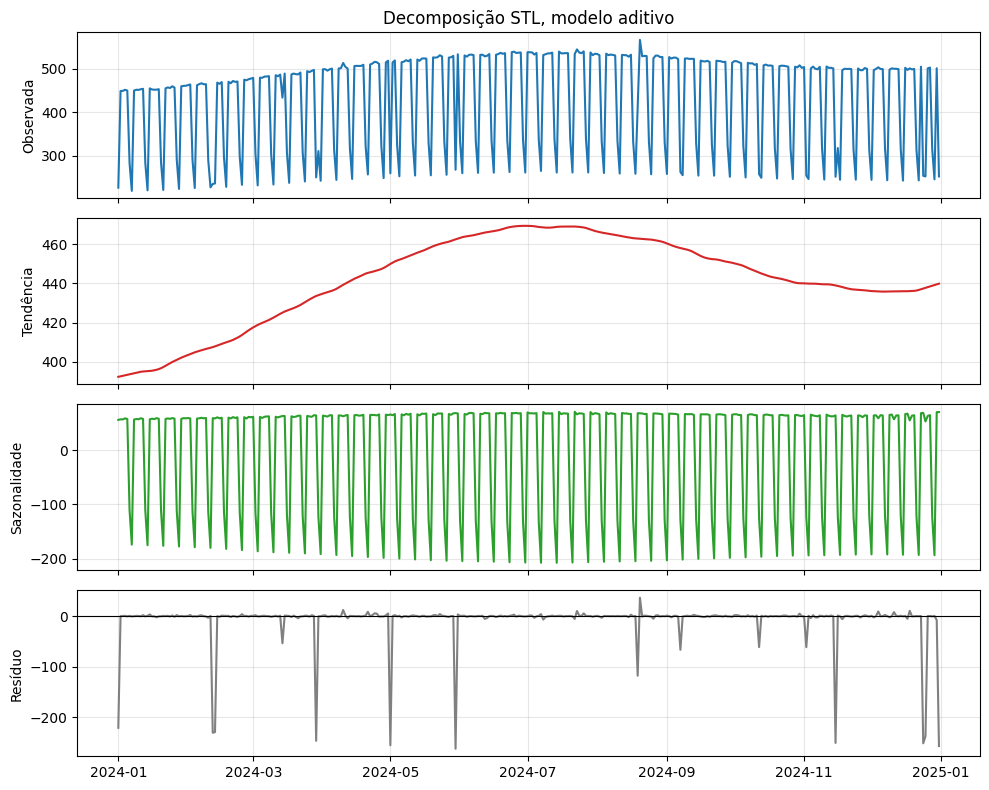

In [ ]:
fig, eixos = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
eixos[0].plot(stl_consumo.observed, color='tab:blue')
eixos[0].set_title('Decomposição STL, modelo aditivo')
eixos[0].set_ylabel('Observada')
eixos[1].plot(stl_consumo.trend, color='tab:red')
eixos[1].set_ylabel('Tendência')
eixos[2].plot(stl_consumo.seasonal, color='tab:green')
eixos[2].set_ylabel('Sazonalidade')
eixos[3].plot(stl_consumo.resid, color='gray')
eixos[3].axhline(0, color='black', linewidth=0.8)
eixos[3].set_ylabel('Resíduo')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Para comparar com a clássica, a mediana do resíduo em valor absoluto (quanto mais perto de 0, menos sobrou da série):

In [ ]:
print('Mediana do resíduo em valor absoluto | clássica:', round(resultado.resid.abs().median(), 1), '| STL:', round(stl_consumo.resid.abs().median(), 1))

Mediana do resíduo em valor absoluto | clássica: 5.5 | STL: 0.6


O efeito dos feriados no resíduo: o resíduo no dia do feriado e nos dois dias antes e depois, nos dois métodos. Os feriados são dias úteis com consumo de fim de semana (01/05, 30/05 e 15/11):

In [ ]:
feriados = ['2024-05-01', '2024-05-30', '2024-11-15']

for dia in feriados:
    dia = pd.Timestamp(dia)

    # o feriado e os 2 dias antes e os 2 dias depois
    janela = slice(dia - pd.Timedelta(days=2), dia + pd.Timedelta(days=2))

    print('Feriado:', dia.date())
    print('  Resíduo da clássica:', resultado.resid[janela].round(0).tolist())
    print('  Resíduo da STL:     ', stl_consumo.resid[janela].round(0).tolist())

Feriado: 2024-05-01
  Resíduo da clássica: [39.0, 43.0, -215.0, 35.0, 43.0]
  Resíduo da STL:      [1.0, 5.0, -255.0, 0.0, 2.0]
Feriado: 2024-05-30
  Resíduo da clássica: [41.0, 44.0, -221.0, 47.0, 28.0]
  Resíduo da STL:      [0.0, 0.0, -262.0, 3.0, 0.0]
Feriado: 2024-11-15
  Resíduo da clássica: [38.0, 33.0, -211.0, 37.0, 32.0]
  Resíduo da STL:      [1.0, -0.0, -250.0, 1.0, -1.0]


**Conclusão:** com o STL, o resíduo fica bem mais perto de 0 na maior parte dos dias.

* **Clássica:** é sensível a pontos atípicos. Os feriados (01/05, 30/05 e 15/11, dias úteis com consumo de fim de semana) contaminam a janela e geram ondulações no resíduo. Nos valores acima, ela espalha o efeito pelos dias vizinhos (resíduos de cerca de +28 a +47)
* **STL robusto:** mantém os vizinhos perto de 0 e deixa o feriado isolado no resíduo, nos picos que sobram
* **Cuidado:** resíduo menor é uma observação, não prova de que o método seja melhor. O que importa é o resíduo parecer ruído

#### 1.3.2 - Modelo multiplicativo

O STL só **soma**. Uma série multiplicativa, $x_t = T_t \times S_t \times R_t$, não tem esse formato, mas o **logaritmo transforma produto em soma**:

$$\log x_t = \log T_t + \log S_t + \log R_t$$

Ou seja, a série $\log x_t$ é **aditiva**. Em um exemplo com três números ($T = 100$, $S = 1{,}2$ e $R = 0{,}98$):

In [ ]:
T, S, R = 100, 1.2, 0.98
print('Log do produto:', round(np.log(T * S * R), 4))
print('Soma dos logs:', round(np.log(T) + np.log(S) + np.log(R), 4))

Log do produto: 4.7673
Soma dos logs: 4.7673


Na série multiplicativa, a amplitude da sazonalidade cresce com o nível. No logaritmo, a amplitude fica quase estável: a série vira aditiva. Aplicando `np.log` ao AirPassengers:

In [ ]:
log_passageiros = np.log(passageiros)
log_passageiros.head()

,Passageiros
Mes,
1949-01-01,4.718499
1949-02-01,4.770685
1949-03-01,4.882802
1949-04-01,4.859812
1949-05-01,4.795791


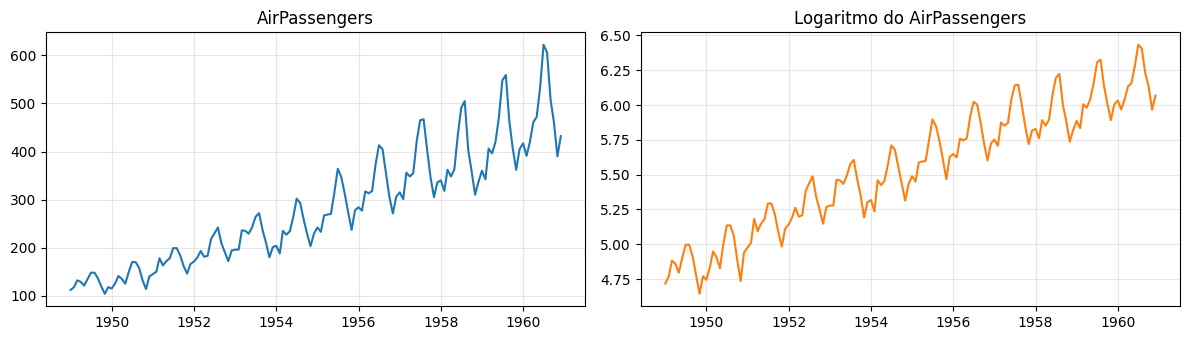

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))
eixos[0].plot(passageiros)
eixos[0].set_title('AirPassengers')
eixos[1].plot(log_passageiros, color='tab:orange')
eixos[1].set_title('Logaritmo do AirPassengers')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Agora aplicamos o STL na série em logaritmo, com `period=12`:

In [ ]:
stl_air = STL(log_passageiros, period=12, robust=True).fit()

Os componentes estão **em logaritmo**, e a soma deles dá o log da série:

In [ ]:
componentes_log = pd.DataFrame({
    'observada': stl_air.observed,
    'tendência': stl_air.trend,
    'sazonalidade': stl_air.seasonal,
    'resíduo': stl_air.resid
})
componentes_log.head()

,observada,tendência,sazonalidade,resíduo
Mes,,,,
1949-01-01,4.718499,4.798486,-0.075233,-0.004755
1949-02-01,4.770685,4.805115,-0.037555,0.003125
1949-03-01,4.882802,4.811788,0.066550,0.004464
1949-04-01,4.859812,4.818520,0.035790,0.005503
1949-05-01,4.795791,4.825323,-0.029277,-0.000255


Para voltar à escala original, o `np.exp` desfaz o logaritmo: como $\exp(\log T + \log S + \log R) = T \times S \times R$, a soma vira o produto. A tendência volta a ser em passageiros, e a sazonalidade e o resíduo viram **fatores** (em torno de 1):

In [ ]:
componentes = np.exp(componentes_log)
componentes.head()

,observada,tendência,sazonalidade,resíduo
Mes,,,,
1949-01-01,112.0,121.326627,0.927527,0.995257
1949-02-01,118.0,122.133531,0.963142,1.003129
1949-03-01,132.0,122.951261,1.068815,1.004474
1949-04-01,129.0,123.781710,1.036438,1.005518
1949-05-01,121.0,124.626682,0.971147,0.999745


In [ ]:
produto = componentes['tendência'] * componentes['sazonalidade'] * componentes['resíduo']
print('Tendência x sazonalidade x resíduo igual à série observada:', bool(np.allclose(produto, passageiros)))

Tendência x sazonalidade x resíduo igual à série observada: True


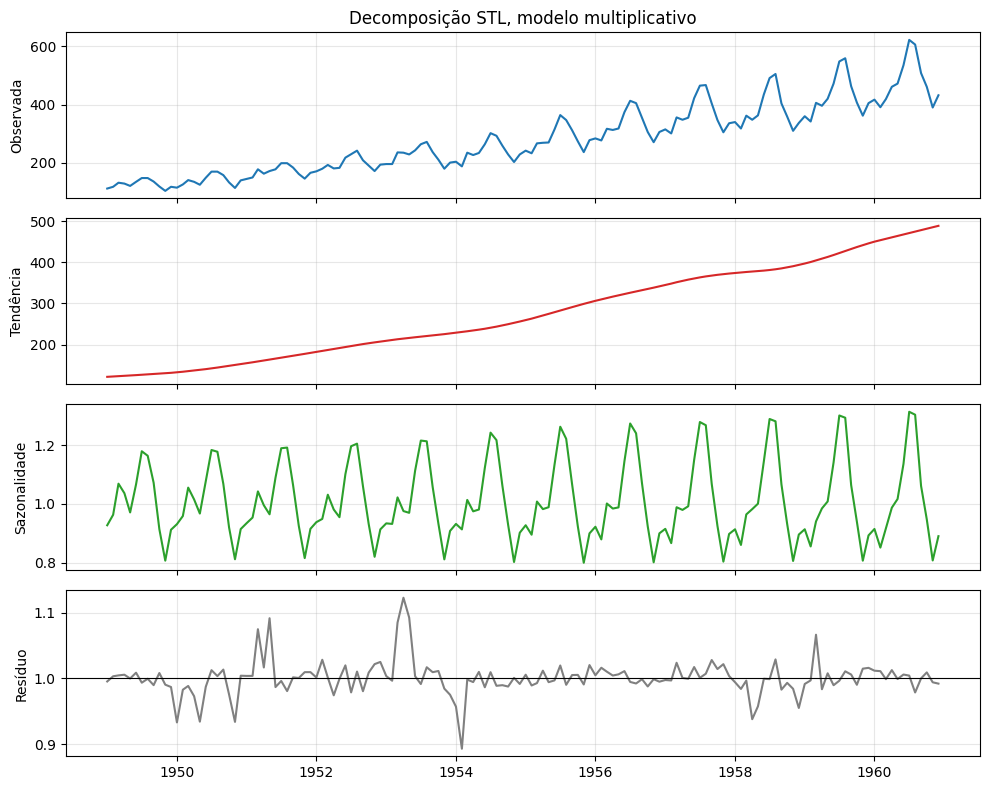

In [ ]:
fig, eixos = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
eixos[0].plot(componentes['observada'], color='tab:blue')
eixos[0].set_title('Decomposição STL, modelo multiplicativo')
eixos[0].set_ylabel('Observada')
eixos[1].plot(componentes['tendência'], color='tab:red')
eixos[1].set_ylabel('Tendência')
eixos[2].plot(componentes['sazonalidade'], color='tab:green')
eixos[2].set_ylabel('Sazonalidade')
eixos[3].plot(componentes['resíduo'], color='gray')
eixos[3].axhline(1, color='black', linewidth=0.8)
eixos[3].set_ylabel('Resíduo')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

No painel da sazonalidade, o padrão **cresce ao longo dos anos**. Na decomposição clássica, era o mesmo em todos os anos.

Para comparar o resíduo dos dois métodos nas duas séries: à esquerda, o modelo aditivo (consumo diário), e à direita, o multiplicativo (AirPassengers). Em cima, a clássica, e embaixo, o STL:

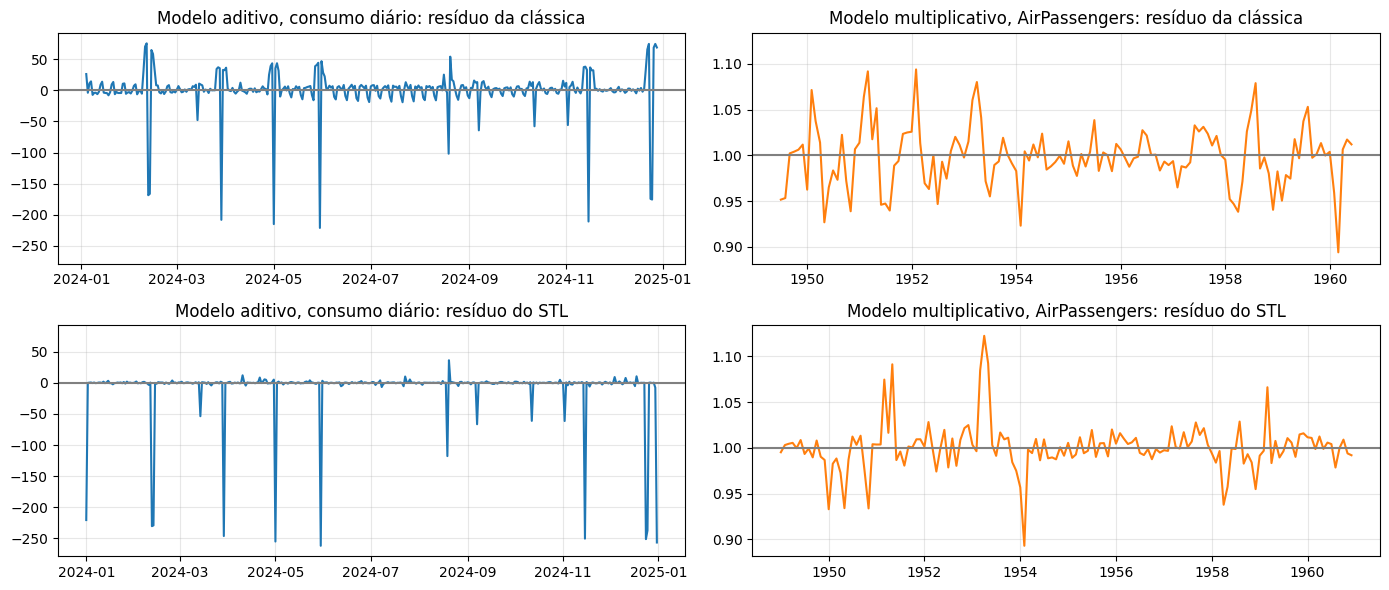

In [ ]:
fig, eixos = plt.subplots(2, 2, figsize=(14, 6), sharey='col')
eixos[0, 0].plot(resultado.resid, color='tab:blue')
eixos[0, 0].set_title('Modelo aditivo, consumo diário: resíduo da clássica')
eixos[1, 0].plot(stl_consumo.resid, color='tab:blue')
eixos[1, 0].set_title('Modelo aditivo, consumo diário: resíduo do STL')
eixos[0, 1].plot(resultado_mult.resid, color='tab:orange')
eixos[0, 1].set_title('Modelo multiplicativo, AirPassengers: resíduo da clássica')
eixos[1, 1].plot(componentes['resíduo'], color='tab:orange')
eixos[1, 1].set_title('Modelo multiplicativo, AirPassengers: resíduo do STL')
for eixo in eixos[:, 0]:
    eixo.axhline(0, color='gray')
for eixo in eixos[:, 1]:
    eixo.axhline(1, color='gray')
for eixo in eixos.flat:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Se o resíduo ainda tivesse padrão sazonal, ele seria parecido com o resíduo do mesmo mês um ano antes. Medimos isso com a correlação do resíduo com ele mesmo deslocado 12 meses (`.shift(12)`, como na Aula 1):

In [ ]:
resid_classica = resultado_mult.resid
resid_stl = componentes['resíduo']
print('Correlação com o resíduo de 12 meses antes | clássica:', round(resid_classica.corr(resid_classica.shift(12)), 2), '| STL:', round(resid_stl.corr(resid_stl.shift(12)), 2))

Correlação com o resíduo de 12 meses antes | clássica: 0.34 | STL: -0.14


**Conclusão:** a clássica deixa padrão sazonal no resíduo (correlação de 0,34 com o mesmo mês do ano anterior), porque supõe a mesma sazonalidade em todos os anos. O STL acompanha a sazonalidade crescente e deixa um resíduo sem esse padrão (correlação de -0,14), mais parecido com ruído, que é o que queríamos.

A decomposição serve para:

* **Entender:** qual componente domina a série
* **Limpar:** tirar a sazonalidade para enxergar a tendência
* **Diagnosticar:** o resíduo mostra o que ficou sem explicação

Mas ela **descreve o passado**. O próximo passo é a **suavização**, que usa só o passado.

## 📌 2 - Médias móveis

A **suavização** é o mesmo cálculo da tendência na decomposição, uma **média de uma janela**, agora com nome. Na decomposição, a janela olhava **antes e depois** de cada ponto. Aqui, a janela olha **só para trás**, porque o futuro não existe. O objetivo é tirar o ruído, chegando até o último ponto observado. Ela descreve o passado e **ainda não é previsão**.

> **Dataset:** uma série **sintética** de consumo, com tendência (+0,8 por período) e ruído, criada para mostrar o efeito de cada média móvel.

In [ ]:
rng = np.random.default_rng(42)
tempo = np.arange(1, 61)
consumo = pd.Series(100 + 0.8 * tempo + rng.normal(0, 7, 60), index=tempo)
consumo.head()

,0
1,102.933020
2,94.320111
3,107.653158
4,109.783953
5,90.342754


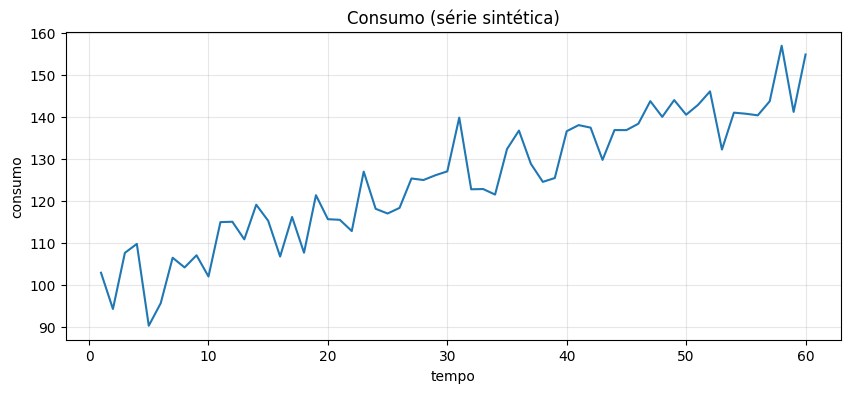

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(consumo.index, consumo.values)
plt.title('Consumo (série sintética)')
plt.xlabel('tempo')
plt.ylabel('consumo')
plt.grid(alpha=0.3)
plt.show()

### 2.1 - Média móvel simples (SMA)

A **SMA** é a média dos $k$ últimos valores, com o mesmo peso para todos:

$$SMA_t = \frac{x_t + x_{t-1} + \dots + x_{t-k+1}}{k}$$

Para entender a ideia, vamos calcular à mão em uma lista pequena, com $k = 3$. Cada ponto é a média dele e dos dois anteriores:

In [ ]:
pequena = pd.Series([10, 12, 11, 13, 15, 14])
pequena

,0
0,10
1,12
2,11
3,13
4,15
5,14


In [ ]:
print('SMA do 3º ponto:', (10 + 12 + 11) / 3)
print('SMA do 4º ponto:', (12 + 11 + 13) / 3)
print('SMA do 5º ponto:', (11 + 13 + 15) / 3)

SMA do 3º ponto: 11.0
SMA do 4º ponto: 12.0
SMA do 5º ponto: 13.0


O método `.rolling(3)` cria uma **janela deslizante** de 3 pontos, e `.mean()` tira a média de cada janela. A janela **termina** no ponto atual: usa só o presente e o passado, que é o que vale para prever. Os dois primeiros pontos ficam sem valor, porque faltam pontos para completar a janela:

In [ ]:
for window in pequena.rolling(3):
    print(list(window))

[10]
[10, 12]
[10, 12, 11]
[12, 11, 13]
[11, 13, 15]
[13, 15, 14]


In [ ]:
pd.DataFrame({'x': pequena, 'SMA (k = 3)': pequena.rolling(3).mean()})

,x,SMA (k = 3)
0,10,NaN
1,12,NaN
2,11,11.0
3,13,12.0
4,15,13.0
5,14,14.0


Os valores são os mesmos que calculamos à mão. Daqui em diante, usamos o `.rolling` direto. Na série `consumo`, com $k = 9$:

In [ ]:
sma9 = consumo.rolling(9).mean()
sma9.head(10)

,0
1,NaN
2,NaN
3,NaN
4,NaN
5,NaN
6,NaN
7,NaN
8,NaN
9,102.053480
10,101.952999


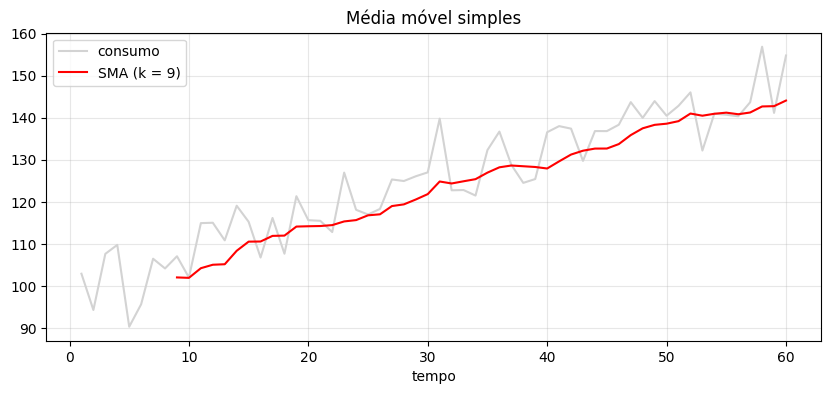

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(consumo.index, consumo.values, color='lightgray', label='consumo')
plt.plot(sma9.index, sma9.values, color='red', label='SMA (k = 9)')
plt.title('Média móvel simples')
plt.xlabel('tempo')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 2.2 - Tamanho da janela

O tamanho $k$ da janela controla a suavização. Para três valores de $k$, vamos medir três coisas: os pontos sem valor, a **variação ponto a ponto** (desvio-padrão das diferenças, que mede o quanto a linha oscila) e a distância média entre o consumo real e a linha suavizada:

In [ ]:
for k in [3, 9, 25]:
    sma = consumo.rolling(k).mean()
    print('k =', k, '| pontos sem valor:', int(sma.isna().sum()), '| variação ponto a ponto:', round(sma.diff().std(), 2), '| real menos suavizada (média):', round((consumo - sma).mean(), 2))

k = 3 | pontos sem valor: 2 | variação ponto a ponto: 2.66 | real menos suavizada (média): 0.91
k = 9 | pontos sem valor: 8 | variação ponto a ponto: 0.89 | real menos suavizada (média): 3.47
k = 25 | pontos sem valor: 24 | variação ponto a ponto: 0.35 | real menos suavizada (média): 9.64


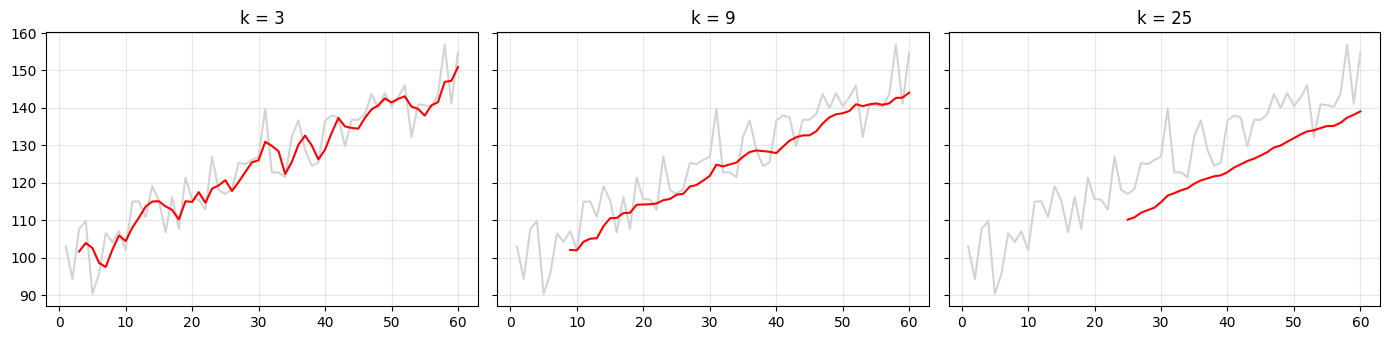

In [ ]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for eixo, k in zip(eixos, [3, 9, 25]):
    eixo.plot(consumo.index, consumo.values, color='lightgray')
    eixo.plot(consumo.index, consumo.rolling(k).mean(), color='red')
    eixo.set_title(f'k = {k}')
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Janela maior deixa a linha **mais suave**, mas com **mais atraso** (a linha fica mais abaixo do real, porque a tendência é de alta) e com menos detalhe.

### 2.3 - Média móvel ponderada (WMA)

Na **WMA**, cada ponto da janela tem um **peso**, e os valores mais recentes pesam mais. Os pesos são escolhidos por nós. Por exemplo, com $k = 3$ e pesos 1, 2 e 3 (o 3 para o valor mais recente):

$$WMA_t = \frac{3x_t + 2x_{t-1} + 1x_{t-2}}{6}$$

Na série `consumo`, vamos usar $k = 9$ e pesos de 1 a 9 (o 9 para o valor mais recente):

In [ ]:
pesos9 = np.arange(1, 10)
pesos9

array([1, 2, 3, 4, 5, 6, 7, 8, 9])

Para a média ponderada, usamos `.apply` depois do `.rolling(9)`: o `.apply` executa uma função em cada janela. Uma média ponderada recebe a **janela** e os **pesos**, então criamos uma função auxiliar com esses dois argumentos. Ela multiplica cada valor pelo seu peso (`np.dot` multiplica par a par e soma) e divide pela soma dos pesos:

In [ ]:
def media_ponderada(janela, pesos):
    return np.dot(janela, pesos) / pesos.sum()

Aplicando a função em cada janela de 9 pontos. Os argumentos do `.apply` estão explicados no código:

In [ ]:
wma9 = consumo.rolling(9).apply(
    # função aplicada em cada janela
    media_ponderada,

    # True: a janela chega à função como vetor do numpy, com o valor mais antigo primeiro (mais rápido)
    # False: a janela chega como Series do pandas, com o índice (mesmo resultado, mais lento)
    raw=True,

    # argumentos extras da função, depois da janela: aqui, os pesos
    args=(pesos9,),
)
wma9.head(12)

,0
1,NaN
2,NaN
3,NaN
4,NaN
5,NaN
6,NaN
7,NaN
8,NaN
9,102.715264
10,102.710307


In [ ]:
print('Real menos suavizada (média) | SMA:', round((consumo - sma9).mean(), 2), '| WMA:', round((consumo - wma9).mean(), 2))

Real menos suavizada (média) | SMA: 3.47 | WMA: 2.37


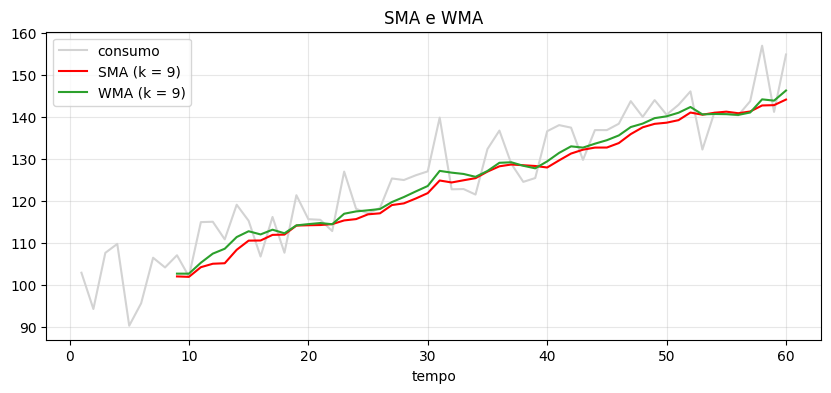

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(consumo.index, consumo.values, color='lightgray', label='consumo')
plt.plot(sma9.index, sma9.values, color='red', label='SMA (k = 9)')
plt.plot(wma9.index, wma9.values, color='tab:green', label='WMA (k = 9)')
plt.title('SMA e WMA')
plt.xlabel('tempo')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

A WMA fica **mais perto do real**: como pesa mais os valores recentes, tem menos atraso.

### 2.4 - Média móvel exponencial (EMA)

Na **EMA**, os pesos **caem exponencialmente** para o passado, e ela usa **todo o histórico**, sem janela fixa. O parâmetro $\alpha$ (entre 0 e 1) é o peso do valor mais recente:

$$EMA_t = \alpha x_t + (1 - \alpha) EMA_{t-1}$$

O método `.ewm(...)` calcula médias com pesos exponenciais, e o `.mean()` devolve a EMA. Os argumentos estão explicados no código. Na série `consumo`, com $\alpha = 0{,}3$:

In [ ]:
ema = consumo.ewm(
    # peso do valor mais recente (entre 0 e 1): o alpha da fórmula
    alpha=0.3,

    # False: usa exatamente a fórmula recursiva acima
    # True (padrão): divide pela soma dos pesos acumulados, o que muda os primeiros pontos
    adjust=False,
).mean()
ema.head()

,0
1,102.933020
2,100.349147
3,102.540350
4,104.713431
5,100.402228


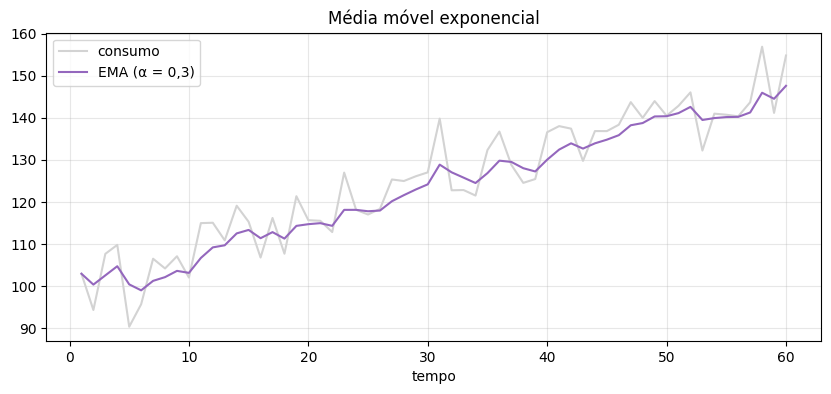

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(consumo.index, consumo.values, color='lightgray', label='consumo')
plt.plot(ema.index, ema.values, color='tab:purple', label='EMA (α = 0,3)')
plt.title('Média móvel exponencial')
plt.xlabel('tempo')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

O nome "exponencial" vem dos pesos: os pesos dos pontos, do mais recente para o mais antigo, são $\alpha$, $\alpha(1 - \alpha)$, $\alpha(1 - \alpha)^2$, e assim por diante. Com $\alpha = 0{,}3$:

In [ ]:
alfa = 0.3
print('Pesos dos 5 últimos pontos:', [round(alfa * (1 - alfa) ** j, 3) for j in range(5)])

Pesos dos 5 últimos pontos: [0.3, 0.21, 0.147, 0.103, 0.072]


### 2.5 - Comparando as médias móveis

As três juntas, na mesma série. À esquerda, a série inteira, e à direita, um zoom no trecho de tempo 30 a 50, onde dá para ver a diferença entre as linhas:

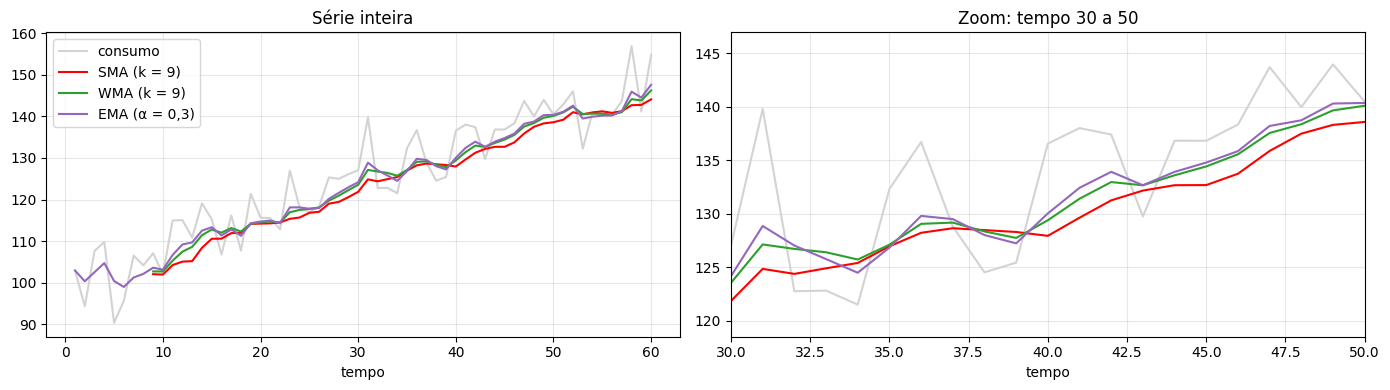

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
for eixo in eixos:
    eixo.plot(consumo.index, consumo.values, color='lightgray', label='consumo')
    eixo.plot(sma9.index, sma9.values, color='red', label='SMA (k = 9)')
    eixo.plot(wma9.index, wma9.values, color='tab:green', label='WMA (k = 9)')
    eixo.plot(ema.index, ema.values, color='tab:purple', label='EMA (α = 0,3)')
    eixo.set_xlabel('tempo')
    eixo.grid(alpha=0.3)
eixos[0].set_title('Série inteira')
eixos[0].legend()
trecho = consumo.loc[30:50]
eixos[1].set_xlim(30, 50)
eixos[1].set_ylim(trecho.min() - 3, trecho.max() + 3)
eixos[1].set_title('Zoom: tempo 30 a 50')
plt.tight_layout()
plt.show()

* **SMA:** pesos iguais, usa os $k$ últimos pontos (parâmetro $k$)
* **WMA:** pesos maiores nos mais recentes, usa os $k$ últimos pontos (parâmetros $k$ e os pesos)
* **EMA:** pesos que caem exponencialmente, usa todo o histórico (parâmetro $\alpha$)

Cada uma tem o seu jeito de lembrar do passado:

* **SMA:** esquece de uma vez, e demora a perceber uma mudança. Boa para série estável
* **WMA:** dá mais atenção ao recente, e percebe a mudança antes. Boa quando você escolhe os pesos
* **EMA:** esquece aos poucos, com o $\alpha$ controlando a velocidade. Boa para dados contínuos, e é a base da SES

Mais peso no recente: reage mais rápido, mas deixa passar mais ruído. Não há a melhor: é um equilíbrio entre suave e rápida.

As três **suavizam**: olham só para o passado e tiram o ruído. **Prever** é olhar para o futuro: estimar valores ainda não observados, para $t$ + 1, $t$ + 2, até o **horizonte** $h$. A conferência da suavização é visual, e a da previsão é comparar com valores reais de teste. É o que vamos fazer a seguir.

## 🎯 Momento de praticar

Suavize o **consumo diário da planta A**, a série da decomposição. Os passos:

1. Recrie a série diária (código abaixo)
2. Calcule a **SMA** com $k = 7$ e com $k = 28$
3. Calcule a **EMA** com $\alpha = 0{,}05$
4. Meça a **variação ponto a ponto** (desvio-padrão das diferenças) da série original e das três médias
5. Plote a série com as três médias: a série inteira e um zoom em um trecho

> **Dica:** o ciclo da série é semanal (7 dias). Por isso usamos $k = 7$ e $k = 28$ (quatro semanas, um múltiplo do ciclo) e um $\alpha$ pequeno, de $0{,}05$.

Para recriar a série, use:

```python
df_a = pd.read_csv(
    PATH + 'datasets/consumo_energia_industrial.csv',
    parse_dates=['timestamp'],
    index_col='timestamp',
)
diario_a = df_a['potencia_kw'].resample('D').mean().interpolate()
```

**Passo 1:** recrie a série diária. Primeiro o dataset puro:

In [ ]:
df_a = pd.read_csv(
    PATH + 'datasets/consumo_energia_industrial.csv',
    parse_dates=['timestamp'],
    index_col='timestamp',
)
df_a.head()

,potencia_kw
timestamp,
2024-01-01 00:00:00,150.2
2024-01-01 00:15:00,143.3
2024-01-01 00:30:00,152.6
2024-01-01 00:45:00,153.6
2024-01-01 01:00:00,138.5


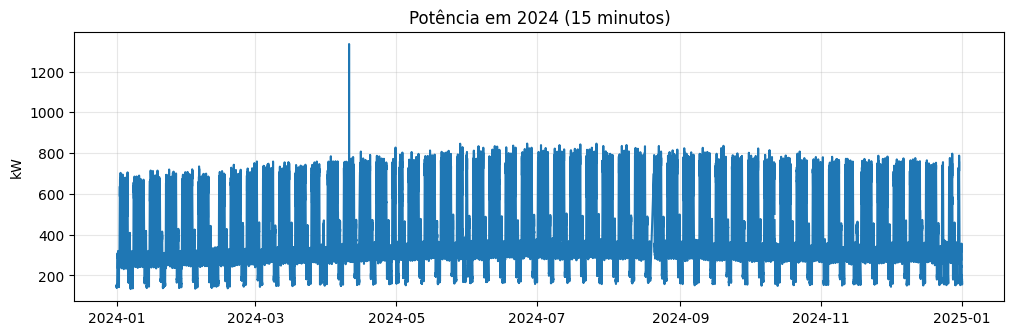

In [ ]:
plt.figure(figsize=(12, 3.5))
plt.plot(df_a.index, df_a['potencia_kw'])
plt.title('Potência em 2024 (15 minutos)')
plt.ylabel('kW')
plt.grid(alpha=0.3)
plt.show()

Com um valor por dia (`resample('D').mean()`), a série fica legível. O `.interpolate()` preenche o dia sem medida:

In [ ]:
diario_a = df_a['potencia_kw'].resample('D').mean().interpolate()
diario_a.head()

,potencia_kw
timestamp,
2024-01-01,227.168750
2024-01-02,448.893750
2024-01-03,449.222917
2024-01-04,451.777083
2024-01-05,449.950000


In [ ]:
print('Número de dias:', len(diario_a))

Número de dias: 366


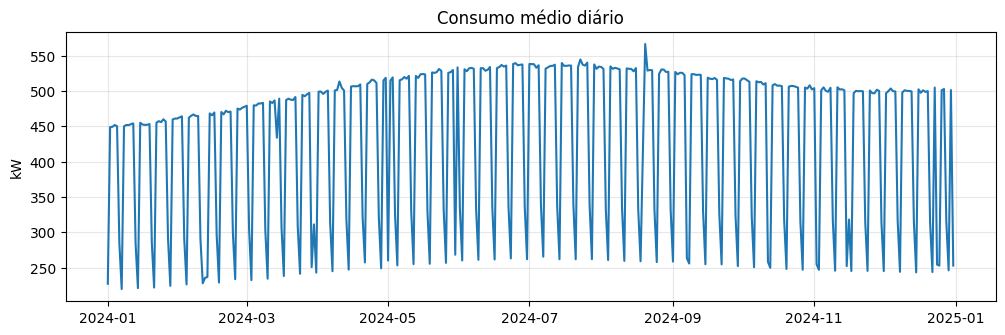

In [ ]:
plt.figure(figsize=(12, 3.5))
plt.plot(diario_a.index, diario_a.values)
plt.title('Consumo médio diário')
plt.ylabel('kW')
plt.grid(alpha=0.3)
plt.show()

**Passo 2:** calcule a SMA com $k = 7$ e com $k = 28$.

In [ ]:
sma7_a = diario_a.rolling(7).mean()
sma28_a = diario_a.rolling(28).mean()
pd.DataFrame({
    'diário': diario_a,
    'SMA (k = 7)': sma7_a,
    'SMA (k = 28)': sma28_a
}).head(10)

,diário,SMA (k = 7),SMA (k = 28)
timestamp,,,
2024-01-01,227.168750,NaN,NaN
2024-01-02,448.893750,NaN,NaN
2024-01-03,449.222917,NaN,NaN
2024-01-04,451.777083,NaN,NaN
2024-01-05,449.950000,NaN,NaN
2024-01-06,284.092632,NaN,NaN
2024-01-07,219.765625,361.552965,NaN
2024-01-08,449.901042,393.371864,NaN
2024-01-09,451.810417,393.788531,NaN


In [ ]:
print('Pontos sem valor | k = 7:', int(sma7_a.isna().sum()), '| k = 28:', int(sma28_a.isna().sum()))

Pontos sem valor | k = 7: 6 | k = 28: 27


**Passo 3:** calcule a EMA com $\alpha = 0{,}05$.

In [ ]:
ema_a = diario_a.ewm(alpha=0.05, adjust=False).mean()
ema_a.head()

,potencia_kw
timestamp,
2024-01-01,227.168750
2024-01-02,238.255000
2024-01-03,248.803396
2024-01-04,258.952080
2024-01-05,268.501976


In [ ]:
print('Pontos sem valor | EMA:', int(ema_a.isna().sum()))

Pontos sem valor | EMA: 0


**Passo 4:** meça a variação ponto a ponto da série original e das três médias.

In [ ]:
for nome, serie in [('original', diario_a), ('SMA (k = 7)', sma7_a), ('SMA (k = 28)', sma28_a), ('EMA (α = 0,05)', ema_a)]:
    print(nome, '| variação ponto a ponto:', round(serie.diff().std(), 1))

original | variação ponto a ponto: 130.5
SMA (k = 7) | variação ponto a ponto: 7.4
SMA (k = 28) | variação ponto a ponto: 2.0
EMA (α = 0,05) | variação ponto a ponto: 5.6


**Passo 5:** plote a série com as três médias. À esquerda, a série inteira, e à direita, um zoom de março a meados de maio.

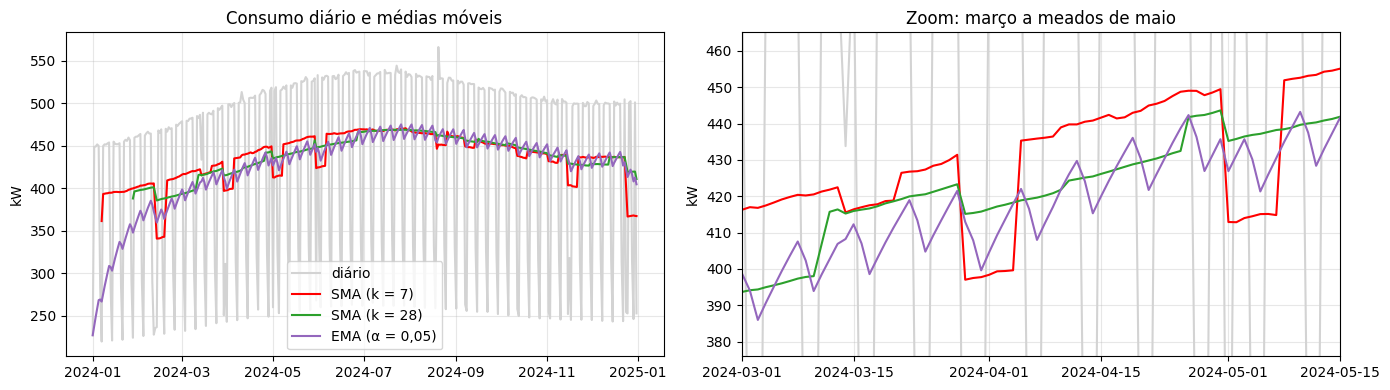

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
for eixo in eixos:
    eixo.plot(diario_a.index, diario_a.values, color='lightgray', label='diário')
    eixo.plot(sma7_a.index, sma7_a.values, color='red', label='SMA (k = 7)')
    eixo.plot(sma28_a.index, sma28_a.values, color='tab:green', label='SMA (k = 28)')
    eixo.plot(ema_a.index, ema_a.values, color='tab:purple', label='EMA (α = 0,05)')
    eixo.set_ylabel('kW')
    eixo.grid(alpha=0.3)
eixos[0].set_title('Consumo diário e médias móveis')
eixos[0].legend()
medias = pd.concat([sma7_a, sma28_a, ema_a], axis=1).loc['2024-03-01':'2024-05-15']
eixos[1].set_xlim(pd.Timestamp('2024-03-01'), pd.Timestamp('2024-05-15'))
eixos[1].set_ylim(medias.min().min() - 10, medias.max().max() + 10)
eixos[1].set_title('Zoom: março a meados de maio')
plt.tight_layout()
plt.show()

**Conclusão:**

* **SMA ($k = 7$):** a variação ponto a ponto cai de 130,5 (série original) para 7,4. A janela cobre uma semana inteira, então o ciclo semanal se cancela. Os degraus que sobram são feriados, que entram e saem da janela. Perde 6 pontos no começo
* **SMA ($k = 28$):** a mais suave (2,0). Quatro semanas são um múltiplo do ciclo, então ele também se cancela, e os feriados pesam menos na janela maior. Perde 27 pontos no começo
* **EMA ($\alpha = 0{,}05$):** variação de 5,6. Não perde pontos, mas só **atenua** o ciclo semanal, em vez de cancelá-lo, porque os pesos não são iguais. Ela começa baixa (parte do primeiro dia, 01/01, um feriado de 227 kW) e leva algumas semanas para alcançar a série

## 📌 3 - Treinamento

Para saber se uma previsão é boa, **reservamos os valores mais recentes** da série, não os usamos para ajustar o modelo e comparamos a previsão com eles.

Voltamos ao AirPassengers, que tem tendência e sazonalidade multiplicativa. Retomando a série `passageiros`:

In [ ]:
passageiros.head()

,Passageiros
Mes,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


### 3.1 - Treino e teste

* **Treino:** os dados usados para ajustar o modelo
* **Teste:** o período mais recente, que o modelo nunca viu

A divisão é **cronológica**: nunca se embaralha uma série (vimos na Aula 1 que a ordem importa).

Antes de separar, definimos o **horizonte** $h$: quantos passos à frente o modelo precisa prever. Como os dados são mensais, $h = 12$ significa prever os próximos 12 meses, e o teste terá exatamente $h$ pontos:

In [ ]:
h = 12
print('Horizonte (h):', h, 'meses')

Horizonte (h): 12 meses


> O horizonte vem da necessidade da operação: a próxima hora, a próxima semana, o próximo trimestre. Quanto maior o horizonte, maior tende a ser o erro.

Separamos as séries com o `.iloc`, que seleciona por **posição** (e não por rótulo). Cada seleção está explicada no código:

In [ ]:
# [:-h]: todas as linhas, menos as h últimas
treino = passageiros.iloc[:-h]

# [-h:]: só as h últimas linhas
teste = passageiros.iloc[-h:]
treino.tail()

,Passageiros
Mes,
1959-08-01,559
1959-09-01,463
1959-10-01,407
1959-11-01,362
1959-12-01,405


In [ ]:
teste.head()

,Passageiros
Mes,
1960-01-01,417
1960-02-01,391
1960-03-01,419
1960-04-01,461
1960-05-01,472


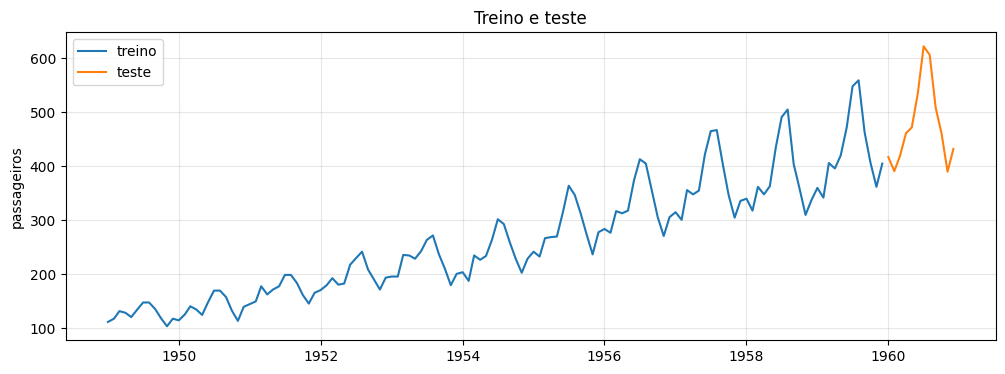

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(treino.index, treino.values, label='treino')
plt.plot(teste.index, teste.values, color='tab:orange', label='teste')
plt.title('Treino e teste')
plt.ylabel('passageiros')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 3.2 - Baseline Naive

O **baseline** é o ponto de comparação: um modelo simples, que todo modelo mais complexo precisa vencer. O **Naive** (previsão ingênua) repete o **último valor** observado, para qualquer horizonte ($\hat{y}_{t+h} = x_t$). Não tem parâmetros nem treino.

No código, criamos uma `Series` com o último valor do treino repetido em cada data do teste:

In [ ]:
naive = pd.Series(treino.iloc[-1], index=teste.index)
naive.head()

,0
Mes,
1960-01-01,405
1960-02-01,405
1960-03-01,405
1960-04-01,405
1960-05-01,405


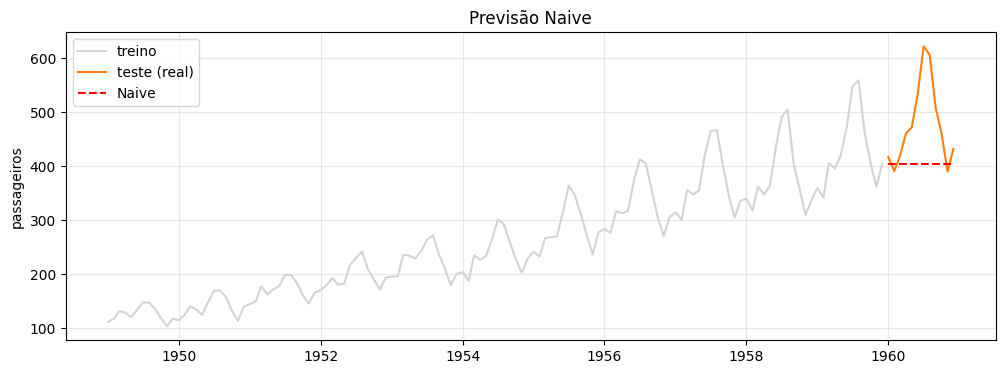

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(treino.index, treino.values, color='lightgray', label='treino')
plt.plot(teste.index, teste.values, color='tab:orange', label='teste (real)')
plt.plot(naive.index, naive.values, color='red', linestyle='--', label='Naive')
plt.title('Previsão Naive')
plt.ylabel('passageiros')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 3.3 - Erros de previsão

Para relembrar, o erro de cada ponto é o real menos o previsto, $e_t = y_t - \hat{y}_t$, e duas métricas resumem os erros, como em Aprendizado de Máquina:

* **MAE** (erro absoluto médio): a média dos erros em valor absoluto, na mesma unidade da série

$$MAE = \frac{1}{n} \sum_{t=1}^{n} |e_t|$$

* **RMSE** (raiz do erro quadrático médio): eleva os erros ao quadrado antes da média, então pesa mais os erros grandes

$$RMSE = \sqrt{\frac{1}{n} \sum_{t=1}^{n} e_t^2}$$

O novo aqui é calcular **só no período de teste**, então $n = h$. Para o Naive:

In [ ]:
erro_naive = teste - naive
erro_naive.head()

,0
Mes,
1960-01-01,12
1960-02-01,-14
1960-03-01,14
1960-04-01,56
1960-05-01,67


In [ ]:
print('MAE do Naive:', round(erro_naive.abs().mean(), 2))
print('RMSE do Naive:', round(np.sqrt((erro_naive ** 2).mean()), 2))

MAE do Naive: 76.0
RMSE do Naive: 102.98


Esses são os números a vencer: um modelo que **não vence o Naive** não vale a complexidade.

## 📌 4 - Suavização exponencial

A suavização exponencial é a EMA **usada para prever**. Três métodos, cada um modelando mais um componente: a **SES** (nível), o **Holt** (nível e tendência) e o **Holt-Winters** (nível, tendência e sazonalidade). Todos serão ajustados no `treino` e avaliados no `teste` do item 3.

### 4.1 - Suavização exponencial simples (SES)

A **SES** estima o **nível** da série. A previsão, para qualquer horizonte, é o **último nível**: uma linha reta. O modelo tem duas equações:

* **Nível:** uma média ponderada entre o valor observado e o nível anterior (a mesma ideia da EMA, item 2.4)

$$\ell_t = \alpha x_t + (1 - \alpha) \ell_{t-1}$$

* **Previsão:** o último nível, para qualquer horizonte $h$

$$\hat{y}_{t+h} = \ell_t$$

Em código, são três etapas. A primeira cria o modelo com `SimpleExpSmoothing`, com os argumentos explicados no código:

In [ ]:
modelo_ses = SimpleExpSmoothing(
    # série de treino
    treino,

    # como obter o nível inicial da série:
    # 'estimated' (estima junto com o alpha), 'heuristic' (regra simples) ou 'known' (valor informado por nós)
    initialization_method='estimated',
)

A segunda ajusta o modelo com `.fit()`: ele procura o $\alpha$ que minimiza o erro no treino. O valor encontrado fica em `.params`:

In [ ]:
ajuste_ses = modelo_ses.fit()
print('α estimado:', round(ajuste_ses.params['smoothing_level'], 3))

α estimado: 1.0


A terceira prevê com `.forecast`, que devolve os próximos valores:

In [ ]:
prev_ses = ajuste_ses.forecast(
    # horizonte: quantos passos à frente prever
    h,
)
prev_ses.round(1).head()

,0
1960-01-01,405.0
1960-02-01,405.0
1960-03-01,405.0
1960-04-01,405.0
1960-05-01,405.0


A previsão é uma **linha reta**: o mesmo valor em todos os meses. Como a série tem tendência, o ajuste escolheu $\alpha \approx 1$ (acompanhar sempre o dado mais recente), e a SES vira o próprio Naive.

No gráfico, a curva verde são os **níveis de cada mês do treino** (`ajuste_ses.fittedvalues`): a equação do nível rodando do primeiro ao último ponto. A previsão (reta vermelha) começa onde ela termina: repete o **último nível**. Como o $lpha$ ficou perto de 1, o nível acompanha quase colado a série:

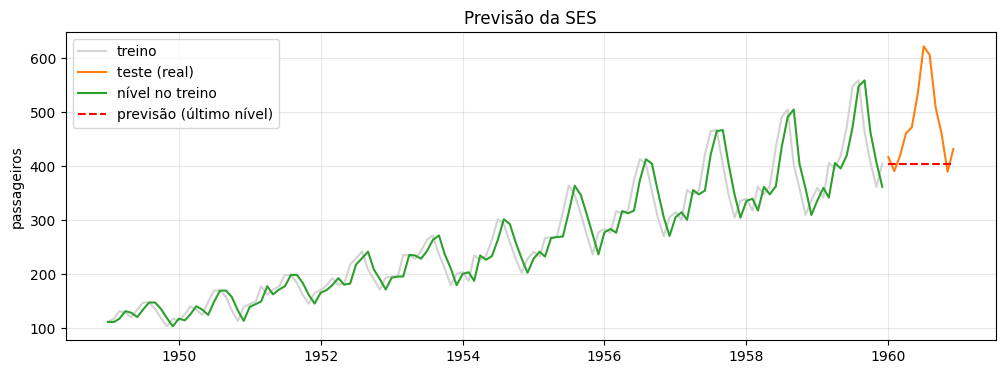

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(treino.index, treino.values, color='lightgray', label='treino')
plt.plot(teste.index, teste.values, color='tab:orange', label='teste (real)')
plt.plot(ajuste_ses.fittedvalues.index, ajuste_ses.fittedvalues.values, color='tab:green', label='nível no treino')
plt.plot(prev_ses.index, prev_ses.values, color='red', linestyle='--', label='previsão (último nível)')
plt.title('Previsão da SES')
plt.ylabel('passageiros')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

> **SES e Naive:** o Naive é o caso particular da SES com $lpha = 1$. Nesse caso, a equação do nível vira $\ell_t = x_t$, e o nível é o último valor observado. Com $lpha < 1$, a SES mistura o último valor com o passado e dilui o ruído do último ponto, o que o Naive não faz.

### 4.2 - Efeito de α

O $\alpha$ controla o peso do dado mais recente. Para ver o efeito, fixamos o $\alpha$ em vez de estimá-lo (os argumentos estão comentados no código). O `.fittedvalues` guarda o nível suavizado em cada ponto do treino. Medimos o erro dessa suavização no treino, nos mesmos três valores de $\alpha$:

In [ ]:
for alfa in [0.1, 0.5, 0.9]:
    ajuste = SimpleExpSmoothing(treino, initialization_method='estimated').fit(
        # valor do alpha, fixado por nós
        smoothing_level=alfa,

        # False: usa o alpha dado, sem procurar o melhor valor
        optimized=False,
    )
    print('α =', alfa, '| erro médio absoluto no treino:', round((treino - ajuste.fittedvalues).abs().mean(), 2))

α = 0.1 | erro médio absoluto no treino: 34.53
α = 0.5 | erro médio absoluto no treino: 28.52
α = 0.9 | erro médio absoluto no treino: 24.63


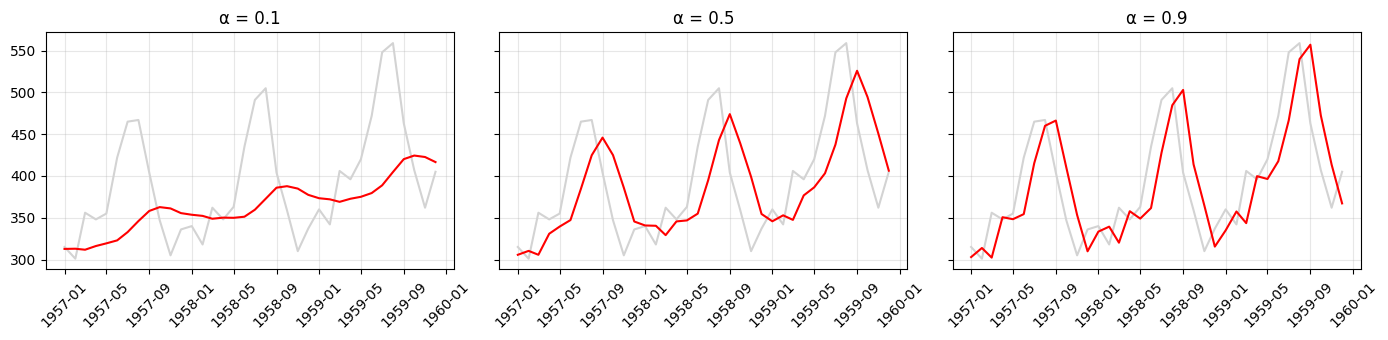

In [ ]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for eixo, alfa in zip(eixos, [0.1, 0.5, 0.9]):
    ajuste = SimpleExpSmoothing(treino, initialization_method='estimated').fit(smoothing_level=alfa, optimized=False)
    eixo.plot(treino.index[-36:], treino.values[-36:], color='lightgray')
    eixo.plot(ajuste.fittedvalues.index[-36:], ajuste.fittedvalues.values[-36:], color='red')
    eixo.set_title(f'α = {alfa}')
    eixo.tick_params(axis='x', rotation=45)
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

* **$\alpha$ pequeno:** nível suave e lento, que demora a acompanhar o dado
* **$\alpha$ grande:** reage rápido, mas acompanha também o ruído

### 4.3 - Método de Holt

A SES supõe uma série **sem tendência** e sem sazonalidade. Com tendência, a previsão fica reta e se afasta do real, como no gráfico da SES (item 4.1).

O **Holt** modela dois componentes: o **nível** ($\ell$) e a **tendência** ($b$, a inclinação). O $\alpha$ atualiza o nível e o $\beta$ atualiza a tendência. A previsão cresce em linha reta, com a inclinação da tendência:

$$\hat{y}_{t+h} = \ell_t + h \cdot b_t$$

Mesmas três etapas, com `Holt(treino)`:

In [ ]:
ajuste_holt = Holt(treino, initialization_method='estimated').fit()
print('α estimado:', round(ajuste_holt.params['smoothing_level'], 3))
print('β estimado:', round(ajuste_holt.params['smoothing_trend'], 3))

α estimado: 1.0
β estimado: 0.0


In [ ]:
prev_holt = ajuste_holt.forecast(h)
prev_holt.round(1).head()

,0
1960-01-01,407.2
1960-02-01,409.5
1960-03-01,411.7
1960-04-01,413.9
1960-05-01,416.2


In [ ]:
print('Aumento por mês na previsão:', round(prev_holt.diff().iloc[1], 2))

Aumento por mês na previsão: 2.24


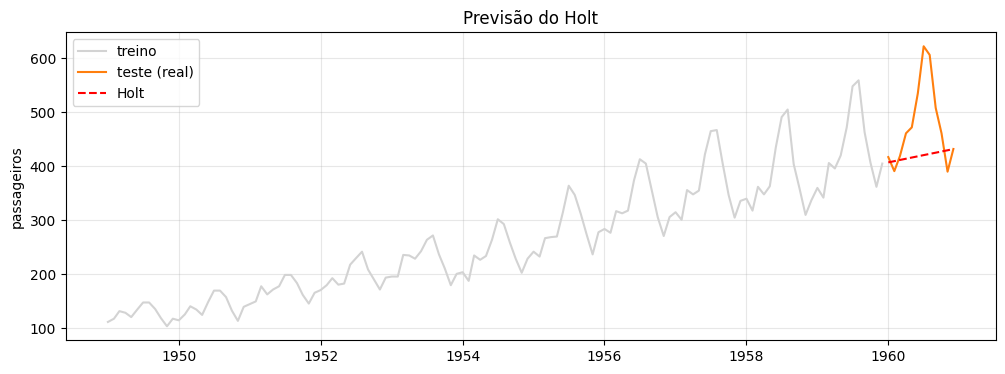

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(treino.index, treino.values, color='lightgray', label='treino')
plt.plot(teste.index, teste.values, color='tab:orange', label='teste (real)')
plt.plot(prev_holt.index, prev_holt.values, color='red', linestyle='--', label='Holt')
plt.title('Previsão do Holt')
plt.ylabel('passageiros')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

A previsão agora **sobe** em linha reta, mas continua sem acompanhar a sazonalidade: falta modelá-la.

### 4.4 - Holt-Winters

O **Holt-Winters** modela **nível, tendência e sazonalidade**. O $\gamma$ atualiza a sazonalidade, com período $m$. A previsão repete o padrão sazonal sobre a tendência (versão aditiva):

$$\hat{y}_{t+h} = \ell_t + h \cdot b_t + s_{t+h-m}$$

A fórmula vale para $h \le m$. Para horizontes maiores, o padrão sazonal volta a se repetir a cada $m$ períodos.

Usamos `ExponentialSmoothing`, com os argumentos explicados no código. A decomposição orienta o tipo da sazonalidade: no AirPassengers, o modelo multiplicativo descreveu melhor os resíduos (item 1.2.3). Começando por ele:

In [ ]:
ajuste_hw = ExponentialSmoothing(
    # série de treino
    treino,

    # tendência: 'add' (somada), 'mul' (multiplicada) ou None (sem tendência)
    trend='add',

    # sazonalidade: 'add' (somada), 'mul' (multiplicada) ou None (sem sazonalidade)
    seasonal='mul',

    # período sazonal m: 12 meses
    seasonal_periods=12,

    # como obter o nível, a tendência e a sazonalidade iniciais ('estimated': estima junto com os parâmetros)
    initialization_method='estimated',
).fit()
print('α estimado:', round(ajuste_hw.params['smoothing_level'], 3))
print('β estimado:', round(ajuste_hw.params['smoothing_trend'], 3))
print('γ estimado:', round(ajuste_hw.params['smoothing_seasonal'], 3))

α estimado: 0.376
β estimado: 0.0
γ estimado: 0.624


In [ ]:
prev_hw = ajuste_hw.forecast(h)
prev_hw.round(1).head()

,0
1960-01-01,417.3
1960-02-01,394.1
1960-03-01,462.4
1960-04-01,448.6
1960-05-01,471.9


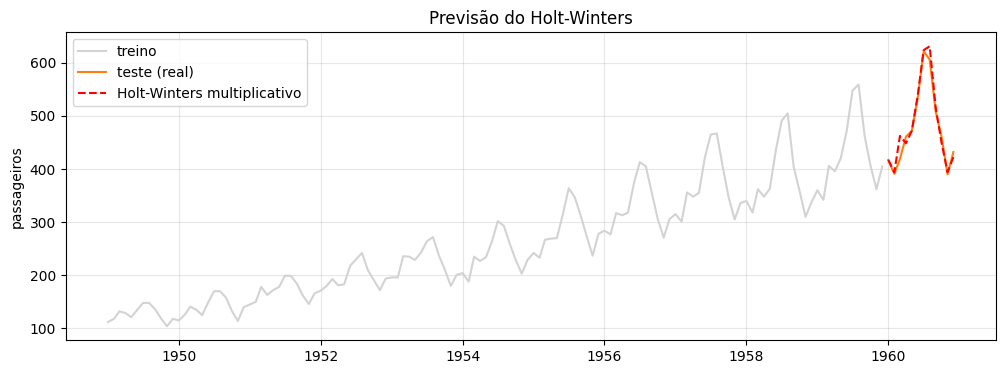

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(treino.index, treino.values, color='lightgray', label='treino')
plt.plot(teste.index, teste.values, color='tab:orange', label='teste (real)')
plt.plot(prev_hw.index, prev_hw.values, color='red', linestyle='--', label='Holt-Winters multiplicativo')
plt.title('Previsão do Holt-Winters')
plt.ylabel('passageiros')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

A previsão agora **acompanha a sazonalidade**. Para ver a diferença entre as duas versões, ajustamos também o Holt-Winters **aditivo** (`seasonal='add'`):

In [ ]:
ajuste_hw_adit = ExponentialSmoothing(treino, trend='add', seasonal='add', seasonal_periods=12, initialization_method='estimated').fit()
prev_hw_adit = ajuste_hw_adit.forecast(h)
prev_hw_adit.round(1).head()

,0
1960-01-01,415.5
1960-02-01,397.1
1960-03-01,457.5
1960-04-01,445.4
1960-05-01,466.2


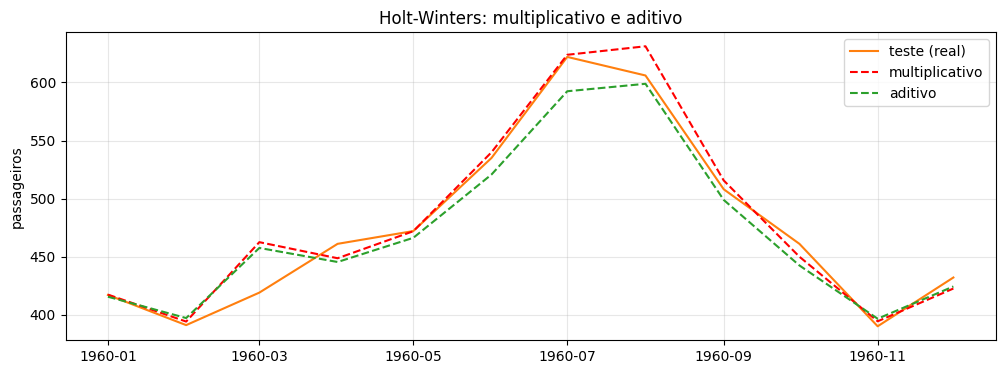

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(teste.index, teste.values, color='tab:orange', label='teste (real)')
plt.plot(prev_hw.index, prev_hw.values, color='red', linestyle='--', label='multiplicativo')
plt.plot(prev_hw_adit.index, prev_hw_adit.values, color='tab:green', linestyle='--', label='aditivo')
plt.title('Holt-Winters: multiplicativo e aditivo')
plt.ylabel('passageiros')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

O tipo identificado na decomposição **orienta a escolha** da versão do Holt-Winters, que deve ser validada pelo erro no teste (item 4.5).

Os parâmetros de suavização controlam:

* **$\alpha$ (nível):** valor alto acompanha o dado recente (e o ruído), e valor baixo deixa o nível suave e lento
* **$\beta$ (tendência):** valor alto muda a inclinação rápido, e valor baixo deixa a inclinação estável
* **$\gamma$ (sazonalidade):** valor alto adapta o padrão sazonal rápido, e valor baixo deixa o padrão estável

Os valores são **estimados pelo modelo**, a partir dos dados de treino. Resumindo os métodos:

* **SES:** modela o nível ($\alpha$), e a previsão é uma linha reta horizontal
* **Holt:** modela nível e tendência ($\alpha$, $\beta$), e a previsão é uma linha reta inclinada
* **Holt-Winters:** modela nível, tendência e sazonalidade ($\alpha$, $\beta$, $\gamma$), e a previsão acompanha a sazonalidade

### 4.5 - Comparação das previsões

Reunimos todas as previsões em uma tabela, uma coluna por modelo:

In [ ]:
previsoes = pd.DataFrame({
    'Naive': naive,
    'SES': prev_ses,
    'Holt': prev_holt,
    'HW aditivo': prev_hw_adit,
    'HW multiplicativo': prev_hw,
})
previsoes.round(1).head()

,Naive,SES,Holt,HW aditivo,HW multiplicativo
1960-01-01,405,405.0,407.2,415.5,417.3
1960-02-01,405,405.0,409.5,397.1,394.1
1960-03-01,405,405.0,411.7,457.5,462.4
1960-04-01,405,405.0,413.9,445.4,448.6
1960-05-01,405,405.0,416.2,466.2,471.9


O método `.rsub` calcula, em cada coluna, `teste - previsão` (o erro do item 3.3). Com os erros, calculamos o MAE e o RMSE de cada modelo no teste:

In [ ]:
erros = previsoes.rsub(
    # série de onde se subtrai a previsão: teste - previsão
    teste,

    # 0: opera coluna a coluna, alinhando as linhas pelas datas
    axis=0,
)
erros.round(1).head()

,Naive,SES,Holt,HW aditivo,HW multiplicativo
1960-01-01,12,12.0,9.8,1.5,-0.3
1960-02-01,-14,-14.0,-18.5,-6.1,-3.1
1960-03-01,14,14.0,7.3,-38.5,-43.4
1960-04-01,56,56.0,47.1,15.6,12.4
1960-05-01,67,67.0,55.8,5.8,0.1


In [ ]:
tabela = pd.DataFrame({
    'MAE': erros.abs().mean(),
    'RMSE': np.sqrt((erros ** 2).mean())
})
tabela.round(2)

,MAE,RMSE
Naive,76.00,102.98
SES,76.00,102.98
Holt,66.31,92.67
HW aditivo,13.38,16.98
HW multiplicativo,10.30,15.81


In [ ]:
print('Menor MAE:', tabela['MAE'].idxmin(), '| valor:', round(tabela['MAE'].min(), 2))
print('Menor RMSE:', tabela['RMSE'].idxmin(), '| valor:', round(tabela['RMSE'].min(), 2))
print('MAE do Naive (baseline):', round(tabela.loc['Naive', 'MAE'], 2))

Menor MAE: HW multiplicativo | valor: 10.3
Menor RMSE: HW multiplicativo | valor: 15.81
MAE do Naive (baseline): 76.0


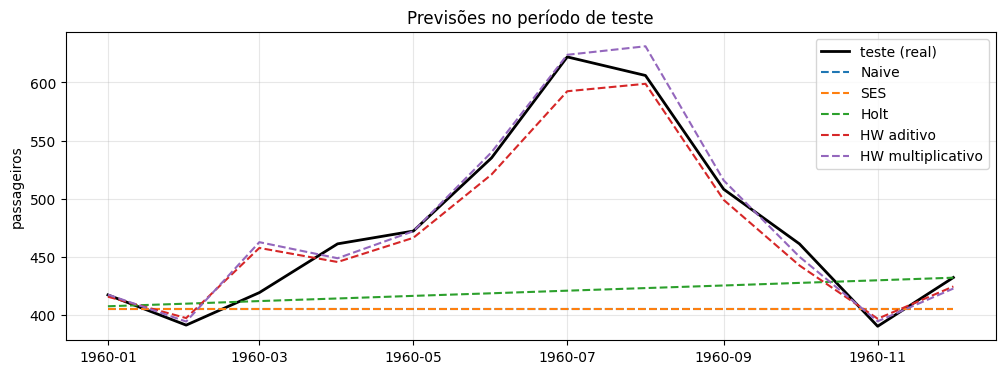

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(teste.index, teste.values, color='black', linewidth=2, label='teste (real)')
for coluna in previsoes.columns:
    plt.plot(previsoes.index, previsoes[coluna], linestyle='--', label=coluna)
plt.title('Previsões no período de teste')
plt.ylabel('passageiros')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Vence o modelo que **erra menos no teste**, desde que supere o baseline. Aqui, o **Holt-Winters multiplicativo** erra cerca de 7 vezes menos que o Naive e a SES (que coincidem, porque o $\alpha$ estimado é 1). O Holt melhora pouco, porque falta a sazonalidade. E a versão aditiva fica atrás da multiplicativa, como a decomposição indicava.

## 🎯 Momento de praticar

Faça a mesma sequência com **outra série**: a temperatura média mensal de Nottingham (1920 a 1939), que a turma conhece da Aula 1. O arquivo tem as colunas `Month` e `Temperature`. Os passos:

1. Carregue o dataset, mostre o início e **plote** a série
2. **Decomponha** a série (modelo aditivo, `period=12`)
3. Separe o **treino** e o **teste** (os últimos 12 meses)
4. Calcule a previsão **Naive**
5. Ajuste o **Holt-Winters** no treino e preveja os 12 meses do teste (a temperatura não tem tendência: use `trend=None`)
6. Calcule o **MAE** e o **RMSE** dos dois modelos no teste
7. Plote o teste com as duas previsões

Para carregar o dataset, use:

```python
df_temp = pd.read_csv(
    PATH + 'datasets/temperatura_media_mensal.csv',
    parse_dates=['Month'],
    index_col='Month',
)
temp = df_temp['Temperature'].asfreq('MS')
```

**Passo 1:** carregue o dataset, mostre o início e plote a série.

In [ ]:
df_temp = pd.read_csv(
    PATH + 'datasets/temperatura_media_mensal.csv',
    parse_dates=['Month'],
    index_col='Month',
)
temp = df_temp['Temperature'].asfreq('MS')
temp.head()

,Temperature
Month,
1920-01-01,40.6
1920-02-01,40.8
1920-03-01,44.4
1920-04-01,46.7
1920-05-01,54.1


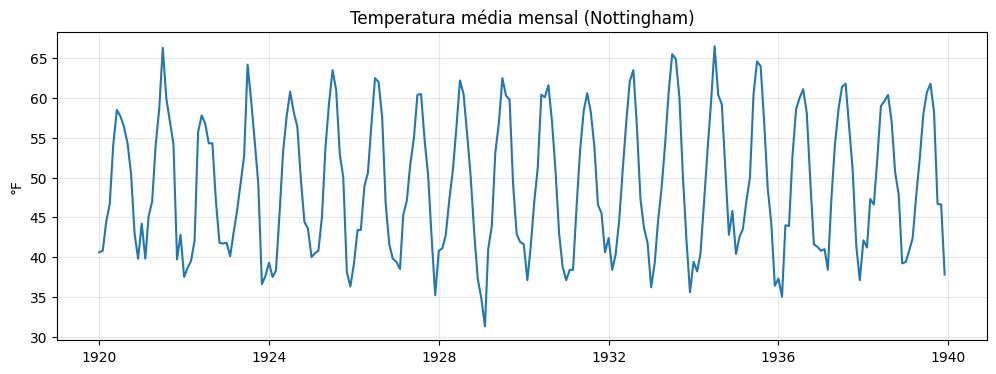

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(temp.index, temp.values)
plt.title('Temperatura média mensal (Nottingham)')
plt.ylabel('°F')
plt.grid(alpha=0.3)
plt.show()

**Passo 2:** decomponha a série (modelo aditivo, `period=12`).

In [ ]:
resultado_temp = seasonal_decompose(temp, model='additive', period=12)
pd.DataFrame({
    'tendência': resultado_temp.trend,
    'sazonalidade': resultado_temp.seasonal,
    'resíduo': resultado_temp.resid
}).dropna().head()

,tendência,sazonalidade,resíduo
Month,,,
1920-07-01,49.041667,12.965461,-4.307127
1920-08-01,49.150000,11.457346,-4.207346
1920-09-01,49.137500,7.393092,-2.230592
1920-10-01,49.179167,0.652961,0.667873
1920-11-01,49.191667,-6.603618,0.311952


In [ ]:
print('Média do resíduo:', round(resultado_temp.resid.mean(), 2))
print('Desvio-padrão do resíduo:', round(resultado_temp.resid.std(), 2))
print('Amplitude da sazonalidade:', round(resultado_temp.seasonal.max() - resultado_temp.seasonal.min(), 1))

Média do resíduo: -0.02
Desvio-padrão do resíduo: 2.08
Amplitude da sazonalidade: 22.9


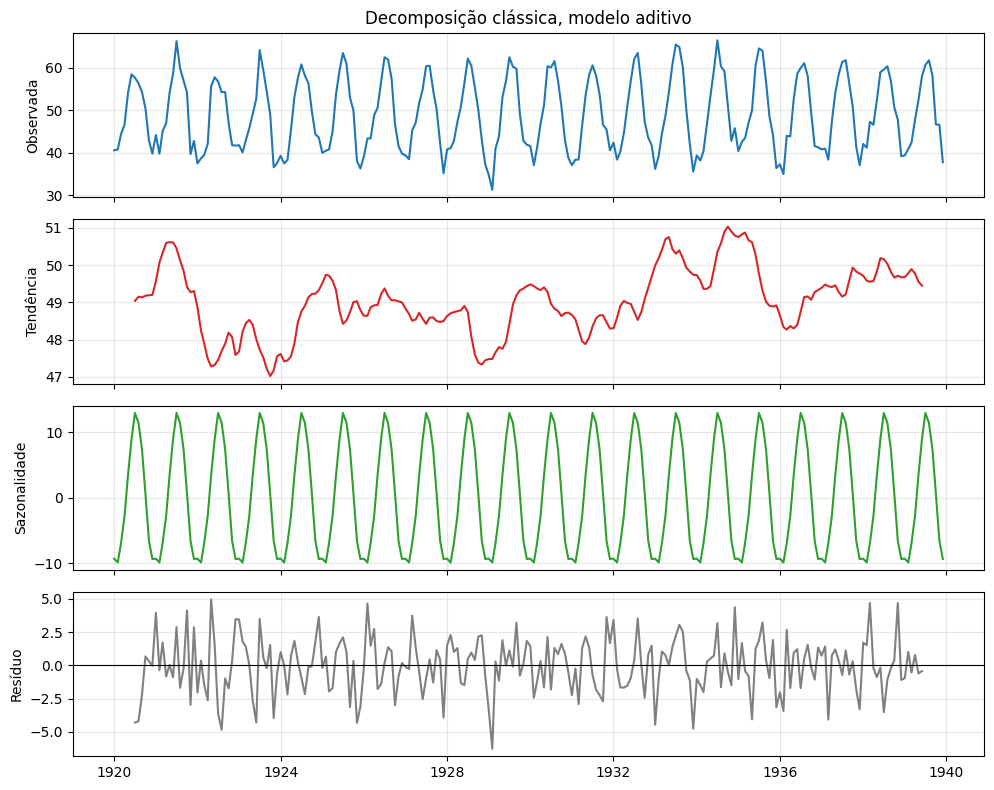

In [ ]:
fig, eixos = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
eixos[0].plot(resultado_temp.observed, color='tab:blue')
eixos[0].set_title('Decomposição clássica, modelo aditivo')
eixos[0].set_ylabel('Observada')
eixos[1].plot(resultado_temp.trend, color='tab:red')
eixos[1].set_ylabel('Tendência')
eixos[2].plot(resultado_temp.seasonal, color='tab:green')
eixos[2].set_ylabel('Sazonalidade')
eixos[3].plot(resultado_temp.resid, color='gray')
eixos[3].axhline(0, color='black', linewidth=0.8)
eixos[3].set_ylabel('Resíduo')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Passo 3:** separe o treino e o teste (os últimos 12 meses).

In [ ]:
treino_t = temp.iloc[:-12]
teste_t = temp.iloc[-12:]
treino_t.tail()

,Temperature
Month,
1938-08-01,60.4
1938-09-01,57.0
1938-10-01,50.7
1938-11-01,47.8
1938-12-01,39.2


In [ ]:
teste_t.head()

,Temperature
Month,
1939-01-01,39.4
1939-02-01,40.9
1939-03-01,42.4
1939-04-01,47.8
1939-05-01,52.4


**Passo 4:** calcule a previsão Naive (o último valor do treino, repetido).

In [ ]:
naive_t = pd.Series(treino_t.iloc[-1], index=teste_t.index)
naive_t.head()

,0
Month,
1939-01-01,39.2
1939-02-01,39.2
1939-03-01,39.2
1939-04-01,39.2
1939-05-01,39.2


**Passo 5:** ajuste o Holt-Winters aditivo, sem tendência, e preveja 12 meses.

In [ ]:
ajuste_t = ExponentialSmoothing(treino_t, trend=None, seasonal='add', seasonal_periods=12, initialization_method='estimated').fit()
prev_t = ajuste_t.forecast(12)
prev_t.round(1).head()

,0
1939-01-01,40.3
1939-02-01,39.7
1939-03-01,42.8
1939-04-01,46.8
1939-05-01,53.2


**Passo 6:** calcule o MAE e o RMSE dos dois modelos no teste.

In [ ]:
previsoes_t = pd.DataFrame({'Naive': naive_t, 'Holt-Winters': prev_t})
erros_t = previsoes_t.rsub(teste_t, axis=0)
erros_t.round(1).head()

,Naive,Holt-Winters
1939-01-01,0.2,-0.9
1939-02-01,1.7,1.2
1939-03-01,3.2,-0.4
1939-04-01,8.6,1.0
1939-05-01,13.2,-0.8


In [ ]:
tabela_t = pd.DataFrame({
    'MAE': erros_t.abs().mean(),
    'RMSE': np.sqrt((erros_t ** 2).mean())
})
tabela_t.round(2)

,MAE,RMSE
Naive,10.42,13.11
Holt-Winters,1.52,1.85


**Passo 7:** plote o teste com as duas previsões.

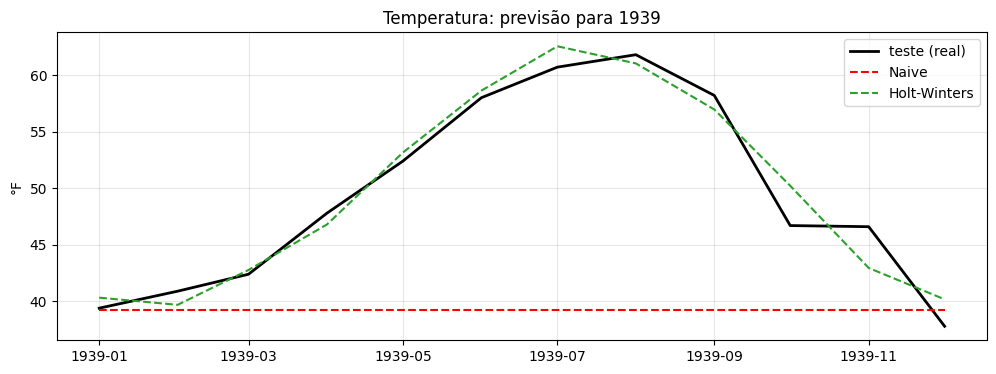

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(teste_t.index, teste_t.values, color='black', linewidth=2, label='teste (real)')
plt.plot(naive_t.index, naive_t.values, color='red', linestyle='--', label='Naive')
plt.plot(prev_t.index, prev_t.values, color='tab:green', linestyle='--', label='Holt-Winters')
plt.title('Temperatura: previsão para 1939')
plt.ylabel('°F')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Conclusão:**

* **Decomposição:** o modelo é **aditivo**. O resíduo oscila em torno de 0 (média de -0,02 °F, desvio-padrão de 2,08 °F) e a sazonalidade tem amplitude de 22,9 °F
* **Naive:** MAE de 10,42 °F e RMSE de 13,11 °F. Ele repete dezembro de 1938 (o mês frio) para todo o ano de 1939
* **Holt-Winters:** MAE de 1,52 °F e RMSE de 1,85 °F, cerca de 7 vezes menos erro. Ele repete o padrão sazonal, e a série não tem tendência
* **Escolha:** o Holt-Winters aditivo supera o baseline com folga

## 📌 Conclusão

* A **decomposição** separa tendência, sazonalidade e resíduo. O resíduo deve parecer ruído, e o modelo (aditivo ou multiplicativo) vem da Aula 1
* O **STL** deixa a sazonalidade mudar ao longo do tempo e não perde pontos nas pontas. Ele só soma, então uma série multiplicativa passa pelo logaritmo (e volta com o `np.exp`)
* As **médias móveis** (SMA, WMA e EMA) suavizam o passado, mas não preveem bem
* A **suavização exponencial** prevê: SES (nível), Holt (tendência) e Holt-Winters (sazonalidade)
* Toda previsão é avaliada no **teste**, em ordem cronológica, contra um **baseline** (o Naive)
* Os modelos estimam os parâmetros ($\alpha$, $\beta$, $\gamma$) a partir do treino, e o melhor é o que erra menos no teste